<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_13_Deploying_Models_in_Production/Chapter_13_Deploying_Models_in_Production.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 13 — Deploying scikit-learn Models in Production

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

A model that lives in a notebook helps nobody. The last chapter of the book moves a trained model **into production**: it must be saved in a form that another process can load, served with an acceptable latency and throughput, watched while the data changes, versioned so that a bad release can be undone, and released through an automated pipeline that refuses to promote a model that is not good enough. The book states plainly that production ML (deployment, monitoring, benchmarking, and the continuous integration / continuous deployment / continuous training cycle, **CI/CD/CT**) makes up "the lion's share of real-world challenges" and that a single chapter can only introduce it. The chapter shows how to:

* **package and persist** a model with `joblib` and `pickle`, and what to be careful about (security, versions, ONNX/PMML);
* **scale** training and prediction with `n_jobs`, `joblib` backends, Dask, and batch serving;
* **monitor** a deployed model on a stream of batches, detect degradation, and update it with `partial_fit`;
* **manage the life cycle** of a model: versioned artifacts, metadata, a validation snapshot;
* **set up a deployment pipeline** in which a `Pipeline` is exported as one artifact and promoted only if a validation threshold is met;
* practise with three exercises.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Overview of model deployment | Yes, 2 listings | What the artifact contains, a round-trip test that actually tests something, the cost of one call against one batch, a minimal prediction service |
| 2 | Serialization and persistence techniques | Yes, 2 listings | Fidelity of the round trip, size and speed of `pickle` and `joblib` (protocols, compression, memory mapping), why unpickling is dangerous and how to restrict it, code that cannot travel with a pickle |
| 3 | Scaling models for production | Yes, 2 listings | Latency against batch size and `n_jobs`, speed-up of training and cross-validation, number of trees against latency, why the book's CV accuracy changes from run to run |
| 4 | Monitoring and updating deployed models | Yes, 2 listings | What the book's "stream" really is, false alarms of a threshold rule, five update policies under a simulated drift, drift alarms against accuracy alarms, what `partial_fit` does |
| 5 | Managing the model life cycle | Yes, 2 listings | The book's validation line fails, honest metadata and a validation snapshot, a verified loader, a simulated library upgrade, a toy registry with rollback, reproducibility |
| 6 | Setting up deployment pipelines | Yes, 2 listings | The gate that can never open, how noisy a threshold gate is, a gate that fails the build, a fuller gate with checks, training-serving skew |
| 7 | Practical exercises in model deployment | Official solutions | Verified round trip in a fresh process, a monitoring exercise that does not degrade the model, a deployment check that rejects for the wrong reason |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook. Extras that report measured times say so in their second line, because those numbers change from run to run.

---
## 0. Setup

Every dataset in this chapter is generated by NumPy and scikit-learn, so the notebook runs offline. The setup cell prints the library versions, defines the plotting style, and moves the notebook into a **scratch directory**: the book's listings write files such as `model.joblib` and `rf.pkl` into the current directory, and this notebook keeps them out of the repository.

**A note on random numbers.** Several listings of the book draw random inputs from NumPy's *global* generator without a seed (`np.random.rand(1, 20)`, `np.random.rand(1000, 50)`, `np.random.randint(0, 2, 100)`), so their output changes at every run. Where that happens, the listing is reproduced unchanged except for one extra first line, `np.random.seed(2024)`, marked `NOT IN THE BOOK`. The extras use their own generators (`np.random.default_rng(...)`) and pass `random_state` to every estimator whose results depend on it, so they never move the global stream that the book's listings depend on. The setup cell also defines two small helpers: `best_time`, the smallest wall-clock time of repeated calls, and `run_python`, which runs a snippet in a **fresh Python process** (the honest way to test that an artifact loads "in another environment").

In [1]:
import json
import os
import pickle
import platform
import subprocess
import sys
import tempfile
import time
import warnings

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"joblib       : {joblib.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# Scratch directory: the files written by the book's listings land here, not in the repository
WORKDIR = tempfile.mkdtemp(prefix="ch13_")
os.chdir(WORKDIR)


def best_time(fn, repeats):
    """Smallest wall-clock time (seconds) of `repeats` calls of fn(): the least disturbed measurement."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)


def run_python(code):
    """Run a snippet in a fresh Python process; return (exit code, stdout, last line of stderr)."""
    done = subprocess.run([sys.executable, "-I", "-W", "ignore", "-c", code], capture_output=True, text=True)
    last_error_line = done.stderr.strip().splitlines()[-1] if done.stderr.strip() else ""
    return done.returncode, done.stdout.strip(), last_error_line


# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
joblib       : 1.6.0
Matplotlib   : 3.11.2


---
## 1. Overview of model deployment

*Book: pp. 332–334.*

### Summary

* **Chapter introduction (p. 331)** — "Everything we've covered up to this point is of little use in the business world if it just sits on your laptop." Models must run in environments that allow "scalability and high throughput while still maintaining predictive performance at or above the business rules that govern them". The CI/CD/CT cycle, monitoring and benchmarking are "the lion's share of real-world challenges", and many of the questions are non-technical (how good must a model be to pay off, when to retrain, whether to use different models for different customers or regions).
* **Recipe** — "Deploying a model means moving it from your development environment into production, so that real users or systems can access its predictions." Deployment means preparing a reliable artifact, serving it with appropriate latency and throughput, and making sure it keeps performing as the data evolves.
* **Getting ready** — a `LogisticRegression` fitted on `make_classification(n_samples=1000, n_features=20, random_state=2024)`.
* **How to do it** — `dump(clf, "model.joblib")`, `clf_loaded = load("model.joblib")`, and a prediction on `np.random.rand(1, 20)`. The book adds: "With only four lines of code, we are able to save, load, and test an ML model using Python's built-in functions."
* **How it works** — `joblib` "is the recommended way to persist scikit-learn models; it handles NumPy arrays efficiently compared to standard pickle"; the exported file can be uploaded to a production server and loaded "by the same library versions", after which the model "behaves identically to the original".
* **There's more** — models are served through REST APIs, batch pipelines or serverless functions, and "bulk prediction ... is far more efficient than one-at-a-time calls due to linear algebra optimizations in NumPy and scikit-learn".
* **Hands-on exercises** — export a logistic regression with `joblib`, simulate a client that loads it and asks for predictions, measure the prediction time for one instance and for a batch, and examine throughput and latency.

### Theory

**What a deployed model is.** A fitted scikit-learn estimator is a Python object with two kinds of attributes: the **hyperparameters** given to the constructor (`C`, `max_iter`, ...) and the **learned state**, whose names end with an underscore (`coef_`, `intercept_`, `classes_`, `n_features_in_`). Persisting a model saves that state. It does **not** save the algorithm: the file records only that "an object of class `sklearn.linear_model._logistic.LogisticRegression` with this state was here", and whoever loads it needs the same class definition. This is why the book insists on loading with "the same library versions", and why a pickle is a *package of data plus a reference to code*.

**The model is a small part of the system.** Sculley et al. (2015) argue that in a real machine-learning system the model code is a small box surrounded by much larger ones: data collection and verification, feature extraction, configuration, serving infrastructure, monitoring. Their central warning is that ML systems incur *technical debt* that is invisible at the code level: boundary erosion, entanglement ("changing anything changes everything"), hidden feedback loops, undeclared consumers, data dependencies and changes in the external world. Breck et al. (2017) turn this into a checklist of 28 tests and monitoring needs, grouped into tests for the data, for the model, for the infrastructure and for monitoring in production.

**Ways to serve a model.**

| Pattern | How it works | Typical latency | Good for | Watch out for |
|---|---|---|---|---|
| Batch (offline) scoring | A scheduled job loads the model and scores a table | minutes to hours | reports, nightly scores, large volumes | scores go stale between runs |
| Online (real-time) service | A web service keeps the model in memory and answers requests | milliseconds | interactive products, fraud checks | cold starts, tail latency, scaling |
| Streaming | A consumer scores events from a queue | sub-second | monitoring, alerting | ordering, back-pressure |
| Embedded / edge | The model ships inside an application or device | microseconds | offline use, privacy | updates are slow, no Python (see ONNX) |
| Serverless | A function loads the model per container start | tens of milliseconds + cold start | spiky traffic | load time counts at every cold start |

**Latency, throughput and the cost of a call.** For most scikit-learn estimators the time of one `predict` call on $m$ rows is well described by
$$T(m) \approx \alpha + \beta\, m,$$
where $\alpha$ is a **fixed cost per call** (input validation, type conversion, Python overhead; also thread-pool start-up for parallel estimators) and $\beta$ is the cost per row. The **latency** that one user sees is $T(1) \approx \alpha$. The **throughput** is $m / T(m)$ rows per second, which tends to $1/\beta$ for large $m$. Batching therefore trades latency for throughput: it divides $\alpha$ among the rows of the batch, but each row waits for the whole batch. Real services care about *percentiles*, not means: Dean and Barroso (2013) show that in a system that fans a request out to many components, the slowest few per cent of calls dominate what users see, so p95 and p99 latencies are what a service-level objective should state.

**Training-serving skew.** The most common reason for a model to fail in production is not the model but a difference between what it saw in training and what it receives when serving: a feature computed differently, columns in another order, a scaler that was not applied. Exporting preprocessing and model **as one object** (recipe 6) removes a whole class of these errors.

**CI/CD/CT.** *Continuous integration* tests every change to the code; *continuous delivery/deployment* releases tested artifacts automatically; *continuous training* (the "CT" the book adds) retrains the model when monitoring shows that it has degraded. Kreuzberger, Kühl and Hirschl (2023) list the principles that make this work: automation, workflow orchestration, reproducibility, versioning of data, model and code, collaboration, continuous training and evaluation, metadata tracking, continuous monitoring and feedback loops. Each recipe of the chapter is one piece of that list:

| Stage | Question | Recipe |
|---|---|---|
| Package | In what form does the model travel? | 1, 2 |
| Serve | How fast, and on how many cores? | 3 |
| Monitor | Is it still right? | 4 |
| Version | Which model is running, and can we go back? | 5 |
| Release | Who decides that a new model may replace the old one? | 6 |

### Book code

The book's two listings: the model (p. 332) and the persistence round trip (p. 333). The second listing draws its test input from the unseeded global generator, so it gets a fixed seed here (`NOT IN THE BOOK`); everything else is the book's code.

In [2]:
# BOOK CODE (p. 332): load the libraries and train a simple model
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train a simple model
X, y = make_classification(
    n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)

LogisticRegression()

In [3]:
# BOOK CODE (p. 333): persist the model with joblib, load it back and predict
np.random.seed(2024)  # NOT IN THE BOOK: the book draws `incoming` from the unseeded global generator

# Save the trained model using joblib
dump(clf, "model.joblib")

# Load the model back
clf_loaded = load("model.joblib")

# Make a prediction with the loaded model
incoming = np.random.rand(1, 20)
print(clf_loaded.predict(incoming))

[1]


**Output analysis.**

* The first listing prints nothing by itself: the last expression, `clf.fit(X, y)`, makes the notebook display the fitted estimator, `LogisticRegression()`.
* The second listing prints `[1]`: the loaded model classifies one random point (drawn from the seeded generator, `NOT IN THE BOOK`) as class 1. That number is not a result of the recipe: the listing compares it with nothing, so it would be printed just the same by a model that was saved wrongly. Extra (a) measures how little a one-point check can detect.

### Extra experiments

**(a) What is in the file, and a round-trip test that tests something.** The cell lists the learned state that the artifact holds, counts the bytes, checks the claim of "Python's built-in functions", and then compares the loaded model with the original on **10,000 random inputs** (all probabilities, not one predicted class). It also builds a deliberately broken copy (all coefficients set to zero) and asks how often the book's single-point check could tell it apart from the real model.

In [4]:
# EXTRA (a): the content of the artifact, "built-in functions", and a round-trip test with real power
import copy

state = clf.__getstate__()
learned = {k: np.shape(v) for k, v in state.items() if k.endswith("_") and k != "_sklearn_version"}
print("learned attributes in the file:", learned)
print("hyperparameters in the file   :", {k: state[k] for k in ("C", "solver", "max_iter", "fit_intercept")})
print("scikit-learn version recorded :", state["_sklearn_version"])
print("file size                     :", os.path.getsize("model.joblib"), "bytes")
print("joblib is part of the standard library:", "joblib" in sys.stdlib_module_names, "| pickle is:", "pickle" in sys.stdlib_module_names)

rng = np.random.default_rng(0)
random_inputs = rng.normal(size=(10_000, 20))
identical = np.array_equal(clf.predict_proba(random_inputs), clf_loaded.predict_proba(random_inputs))
print(f"\nloaded and original agree exactly on all 10,000 probabilities: {identical}")

broken = copy.deepcopy(clf_loaded)
broken.coef_[:] = 0.0  # a "corrupted" artifact: the model now only uses its intercept
agree = np.mean(broken.predict(random_inputs) == clf.predict(random_inputs))
print(f"broken copy gives the same class as the real model on {agree:.1%} of random inputs")
print(f"-> a one-point check (the book) misses the corruption with probability {agree:.1%}; 10,000 probabilities miss it with probability 0")

learned attributes in the file: {'n_features_in_': (), 'classes_': (2,), 'n_iter_': (1,), 'coef_': (1, 20), 'intercept_': (1,)}
hyperparameters in the file   : {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 100, 'fit_intercept': True}
scikit-learn version recorded : 1.9.1
file size                     : 1007 bytes
joblib is part of the standard library: False | pickle is: True

loaded and original agree exactly on all 10,000 probabilities: True
broken copy gives the same class as the real model on 54.9% of random inputs
-> a one-point check (the book) misses the corruption with probability 54.9%; 10,000 probabilities miss it with probability 0


**Analysis of extra (a).**

* The artifact is a file of **1,007 bytes**. It holds the learned state of the model (`coef_` with shape (1, 20), `intercept_`, `classes_`, `n_iter_`, `n_features_in_`), the hyperparameters, and the version of scikit-learn that wrote it (`_sklearn_version`, here 1.9.1): data about the model, not code.
* The text speaks of "Python's built-in functions": `joblib` is **not** in the standard library (`"joblib" in sys.stdlib_module_names` is `False`; `pickle` is in it). `joblib` is a dependency of scikit-learn, so it is always present next to it, but it is a separate package with its own version.
* The loaded model and the original agree **exactly** on all 10,000 probabilities: saving and loading a linear model loses nothing.
* A deliberately broken copy (all coefficients set to zero, so that it only uses its intercept) gives the same class as the real model on **54.9%** of random normal inputs. A check that compared the class of one random point would therefore miss such a corruption with a probability of about 55% (the book's own listing compares nothing, and draws uniform points, so the exact figure depends on the inputs, but not the order of magnitude); comparing 10,000 probabilities misses it with probability zero. A round-trip test should compare many inputs and compare probabilities, not a single class.

 batch size  time of the call (us)  time per row (us)  rows per second
          1                 99.933             99.933        10006.704
         10                 98.368              9.837       101659.076
        100                101.453              1.015       985678.099
       1000                114.981              0.115      8697089.082
      10000                251.806              0.025     39713112.467
     100000               2224.986              0.022     44944103.022

fixed cost per call alpha = 100 us; cost per row beta = 0.0219 us
one row costs 869 times more per row than a batch of 1,000


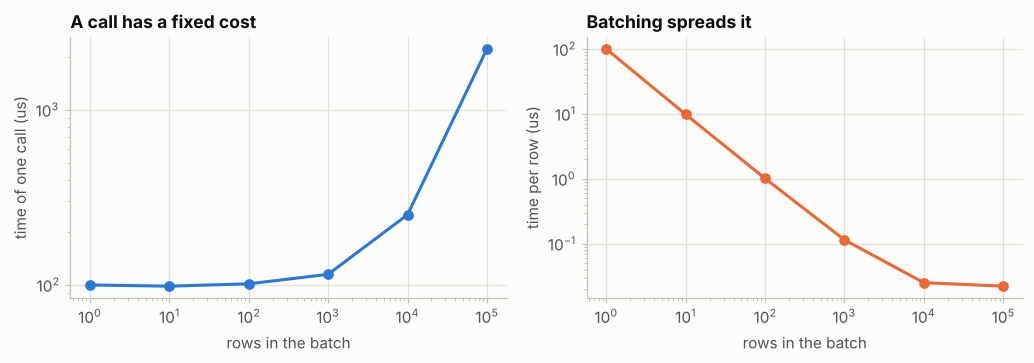

In [5]:
# EXTRA (b): latency of one call as a function of the batch size
# (timings: the numbers below change from run to run)
sizes = [1, 10, 100, 1_000, 10_000, 100_000]
pool = np.random.default_rng(1).normal(size=(max(sizes), 20))
per_call = np.array([best_time(lambda m=m: clf_loaded.predict(pool[:m]), 200 if m <= 1_000 else 30) for m in sizes])
per_row = per_call / np.array(sizes)

alpha = per_call[0]
beta = (per_call[-1] - per_call[-2]) / (sizes[-1] - sizes[-2])
table = pd.DataFrame({"batch size": sizes, "time of the call (us)": per_call * 1e6, "time per row (us)": per_row * 1e6,
                      "rows per second": np.array(sizes) / per_call})
print(table.round(3).to_string(index=False))
print(f"\nfixed cost per call alpha = {alpha * 1e6:.0f} us; cost per row beta = {beta * 1e6:.4f} us")
print(f"one row costs {per_row[0] / per_row[3]:.0f} times more per row than a batch of 1,000")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].loglog(sizes, per_call * 1e6, marker="o", color=PALETTE[0])
axes[0].set_xlabel("rows in the batch")
axes[0].set_ylabel("time of one call (us)")
axes[0].set_title("A call has a fixed cost")
axes[1].loglog(sizes, per_row * 1e6, marker="o", color=PALETTE[1])
axes[1].set_xlabel("rows in the batch")
axes[1].set_ylabel("time per row (us)")
axes[1].set_title("Batching spreads it")
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* A call of `predict` on the logistic regression takes about **100 microseconds whether the batch has 1, 10 or 100 rows**, a little more for 1,000 rows, a few hundred microseconds for 10,000 and about 2 milliseconds for 100,000 (the figures change a little from run to run, the shape does not). The time of a call is a **fixed cost** of about 100 microseconds (alpha) plus about 0.02 microseconds per row (beta).
* The time **per row** therefore falls from about 100 microseconds for a single row to about 0.1 microsecond for 1,000 rows: a row costs roughly 900 times more when it is predicted alone than inside a batch of 1,000 (the exact factor changes from run to run, but it is above 100 on any machine that runs this model). In rows per second the model goes from about 10,000 (single rows) to tens of millions (batches of 100,000).
* This is the whole content of the book's remark that bulk prediction is "far more efficient than one-at-a-time calls": the efficiency is not in the linear algebra, which is trivial here, but in the **fixed cost** that a batch spreads over its rows. The price is latency: a row inside a large batch waits for the whole batch.

**(c) A minimal prediction service.** The hands-on exercise of the book asks to "simulate a prediction endpoint". The class below keeps the model in memory, **validates every request** (right number of columns, no missing or infinite values) and answers with a list of classes. The cell compares three ways of answering the same 200 rows: 200 requests that each load the model from disk, 200 single-row requests to a service that loaded it once, and one request of 200 rows; it also shows what the validation catches.

In [6]:
# EXTRA (c): a minimal prediction service, and what loading per request costs
# (timings: the numbers below change from run to run)
class PredictionService:
    """Loads the model once, validates the payload, predicts."""

    def __init__(self, path):
        self.model = load(path)
        self.n_features = self.model.n_features_in_

    def predict(self, rows):
        rows = np.asarray(rows, dtype=float)
        if rows.ndim != 2 or rows.shape[1] != self.n_features:
            raise ValueError(f"expected rows with {self.n_features} values, got shape {rows.shape}")
        if not np.isfinite(rows).all():
            raise ValueError("payload contains missing or infinite values")
        return self.model.predict(rows).tolist()


service = PredictionService("model.joblib")
requests = np.random.default_rng(2).normal(size=(200, 20))

t_cold = best_time(lambda: [PredictionService("model.joblib").predict(requests[i:i + 1]) for i in range(200)], 3)
t_single = best_time(lambda: [service.predict(requests[i:i + 1]) for i in range(200)], 5)
t_batch = best_time(lambda: service.predict(requests), 30)
same = [PredictionService("model.joblib").predict(requests[i:i + 1])[0] for i in range(200)] == service.predict(requests)

print(pd.DataFrame({"way of answering 200 rows": ["200 requests, model loaded at every request", "200 single-row requests, model loaded once", "one request with 200 rows"],
                    "total time (ms)": np.array([t_cold, t_single, t_batch]) * 1e3,
                    "relative to the batch": np.array([t_cold, t_single, t_batch]) / t_batch}).round(2).to_string(index=False))
print("the three ways give the same classes:", same)

for payload in ([[0.0] * 19], [[0.0] * 19 + [np.nan]], [[0.0] * 20]):
    try:
        print("accepted ->", service.predict(payload))
    except ValueError as error:
        print("rejected ->", error)

                  way of answering 200 rows  total time (ms)  relative to the batch
200 requests, model loaded at every request           117.49                1042.05
 200 single-row requests, model loaded once            34.77                 308.41
                  one request with 200 rows             0.11                   1.00
the three ways give the same classes: True
rejected -> expected rows with 20 values, got shape (1, 19)
rejected -> payload contains missing or infinite values
accepted -> [0]


**Analysis of extra (c).**

* The same 200 rows are answered in three ways: 200 requests that each **load the model from disk** (tens of milliseconds, several hundred times the time of the batch), 200 single-row requests to a service that loaded the model **once** (a few tens of milliseconds, about 200 to 250 times the batch), and **one request with 200 rows** (about a tenth of a millisecond). The three ways give the same classes. Loading at every request, which is what a naive serverless function does at each cold start, costs roughly 3 times more than keeping the model in memory (2.8 to 3.5 in the runs of this notebook), and single-row requests cost about 200 times more than one batch.
* The validation turns two bad payloads into explicit errors: a row with 19 values (`expected rows with 20 values, got shape (1, 19)`) and a row with a missing value are **rejected** before they reach the model; the well-formed row is accepted. A real service also needs authentication, a timeout, logging of every request with the model version, and a health check; none of that is scikit-learn, but all of it is part of "deployment".

---
## 2. Serialization and persistence techniques

*Book: pp. 334–336.*

### Summary

* **Recipe** — "Saving and reloading models is essential for production workflows—training usually happens once in a given CI/CD/CT cycle, but prediction must happen repeatedly." The recipe serializes a model with `pickle` and with `joblib`, discusses security and versioning, and mentions third-party formats such as the Open Neural Network Exchange (**ONNX**) for Python-free environments.
* **Getting ready** — a `RandomForestClassifier(n_estimators=10, random_state=2024)` fitted on `make_classification(n_samples=500, n_features=15, random_state=2024)`.
* **How to do it** — five steps: `pickle.dump` to `rf.pkl`, `dump(rf, "rf.joblib")`, load both, and two `assert np.array_equal(...)` on the predictions for the first five rows. The book says the output of each technique "should produce the same model we stored earlier" and that the aim is to "convert our models into Python arrays".
* **How it works** — `pickle` "works for serializing objects but can struggle with large NumPy arrays inside estimators"; `joblib.dump` and `joblib.load` are "optimized for such cases and are the recommended serialization methods". Trust is required when unpickling ("never use untrusted files"), models saved with one scikit-learn version "may break if loaded with a different version", and converters to ONNX or Predictive Model Markup Language (PMML) exist for contexts without Python, "although these formats may not support all scikit-learn estimators".
* **Serialization (sidebar)** — turns the model "into a byte stream ... a series of binary values", which "helps compress and store ML models" and allows "mobility".
* **There's more** — snapshot the code, library versions, training data and validation outputs; use `cloudpickle` "when standard pickle/joblib serialization fails (e.g., with custom or dynamically generated estimators)".
* **Hands-on exercises** — serialize with both libraries, restore them "in separate Python sessions", compare outputs, and explore exporting to ONNX with the `skl2onnx` package.

### Theory

**What pickle does.** `pickle` turns an object graph into a byte stream for a small stack machine: loading *executes* that stream. The stream contains instructions such as "import the name `RandomForestClassifier` from the module `sklearn.ensemble._forest`" (opcode `GLOBAL`, written `STACK_GLOBAL` since protocol 4), "build an object of that class" and "restore this state dictionary" (`BUILD`). Three consequences follow, and they organize the rest of the recipe.

1. **Classes and functions are saved by name, not by value.** Only the module path and the name travel. Loading needs the same code to be importable under the same name; a function defined in an interactive session or a lambda cannot be found in another process.
2. **Loading runs code.** An object may define `__reduce__` to say "to rebuild me, call this callable with these arguments", and the callable can be anything: `os.system`, `print`, `subprocess.run`. `pickle.load` on a file you do not trust is therefore equivalent to running a program you do not trust. The Python documentation states it plainly ("The pickle module is not secure. Only unpickle data you trust") and scikit-learn's documentation applies the warning to `joblib` and `cloudpickle`, which use the same format.
3. **The state is whatever the library keeps in the object today.** scikit-learn stores its version in the state (`_sklearn_version`) and warns with `InconsistentVersionWarning` when a model is loaded by another version; its documentation adds that loading a model trained with a different version is "entirely unsupported and inadvisable", because attributes may be renamed, removed or reinterpreted.

**pickle against joblib.** `joblib.dump` is a pickler specialised for objects that hold large NumPy arrays: it writes each large array as a raw binary buffer (instead of copying it into the byte stream), optionally compresses (`compress=0..9`, `3` is "often a good compromise"), and can later **memory-map** the arrays (`load(..., mmap_mode="r")`) so that several worker processes share one copy of the model. The claim that plain pickle "struggles with large NumPy arrays" is true of old protocols; since Python 3.8 **pickle protocol 5** (PEP 574) handles large buffers efficiently, and the scikit-learn documentation now says that `pickle` "can also be very efficient memorywise if the model was persisted with `protocol=5` but it does not support memory mapping". The extras measure it: the real advantages of `joblib` are compression and memory mapping, not speed.

**Formats beyond pickle.**

| Format | What it stores | Runs code on load? | Limits |
|---|---|---|---|
| `pickle`, `joblib`, `cloudpickle` | the Python object graph | **yes** | same Python and library versions; `cloudpickle` also saves lambdas and interactive functions by value, with no compatibility guarantee across versions |
| `skops.io` | the same state in a non-executable format | no: unknown types must be trusted explicitly (`get_untrusted_types`) | scikit-learn estimators; still tied to the library version |
| ONNX | a computation graph of standard operators (with `skl2onnx`) | no (but it can describe arbitrary computation; run it sandboxed) | not every estimator or custom step converts; inference only |
| PMML | an XML description of the model | no | older, narrower operator coverage |

This notebook runs only `pickle` and `joblib`: `skops`, `skl2onnx` and `onnxruntime` are not part of the dependencies of the book or of this repository.

**What makes an artifact large or slow to load.** A tree ensemble stores every node of every tree, so its size grows with `n_estimators` and with the depth and number of leaves of each tree (and hence with the amount of training data when trees are grown fully); a linear model stores one coefficient per feature; a nearest-neighbours model stores the entire training set. Size matters for load time (cold starts of a serverless function), memory per worker, and transfer to the server.

**Integrity.** A file can be corrupted or replaced. Recording a **cryptographic hash** (SHA-256) of the artifact next to its metadata detects corruption, and signing it with a keyed hash (`hmac`) detects replacement by someone who lacks the key; the Python documentation recommends signing for this purpose. Neither makes it safe to load a file from a source you do not control.

### Book code

The book's two listings: the model (p. 334) and the serialization with both libraries (p. 335). The files `rf.pkl` and `rf.joblib` are written to the scratch directory of the setup cell.

In [7]:
# BOOK CODE (p. 334): load the libraries and train a classifier
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import pickle
from joblib import dump, load

# Train a classifier
X, y = make_classification(
    n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(
    n_estimators=10, random_state=2024)
rf.fit(X, y)

RandomForestClassifier(n_estimators=10, random_state=2024)

In [8]:
# BOOK CODE (p. 335): serialize with pickle and with joblib, load both and compare the predictions
# Serialize using pickle
with open("rf.pkl", "wb") as f:
    pickle.dump(rf, f)

# Serialize using joblib
dump(rf, "rf.joblib")

# Load the pickle model
with open("rf.pkl", "rb") as f:
    rf1 = pickle.load(f)

# Load the joblib model
rf2 = load("rf.joblib")

# Ensure identical behavior after loading
assert np.array_equal(rf.predict(X[:5]),
                      rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]),
                      rf2.predict(X[:5]))

**Output analysis.**

* The first listing displays the fitted forest, `RandomForestClassifier(n_estimators=10, random_state=2024)`. The second prints nothing: the two `assert` statements passed. What they check is small: the **classes of five rows**.
* The book speaks of converting "our models into Python arrays". The two listings write **two files**, `rf.pkl` (58,325 bytes) and `rf.joblib` (59,241 bytes): a byte stream on disk, not arrays (extra (a)).

### Extra experiments

**(a) How faithful is the round trip?** The book's assertions compare the **class** predicted for five rows. The cell compares the **class probabilities** of the three forests on 10,000 random inputs, and the internal arrays of all ten trees (split features, thresholds, leaf values), and reports the file sizes.

In [9]:
# EXTRA (a): fidelity of the round trip, beyond five predicted classes
probe = np.random.default_rng(3).normal(size=(10_000, 15))
p_original = rf.predict_proba(probe)
print("probabilities identical, pickle :", np.array_equal(p_original, rf1.predict_proba(probe)))
print("probabilities identical, joblib :", np.array_equal(p_original, rf2.predict_proba(probe)))

same_trees = all(
    np.array_equal(getattr(a.tree_, name), getattr(b.tree_, name))
    for a, b in zip(rf.estimators_, rf2.estimators_)
    for name in ("feature", "threshold", "value", "children_left", "children_right"))
print("all 10 trees have identical arrays after joblib:", same_trees)
print("nodes in the 10 trees:", sum(t.tree_.node_count for t in rf.estimators_))
print(f"file sizes: rf.pkl {os.path.getsize('rf.pkl'):,} bytes, rf.joblib {os.path.getsize('rf.joblib'):,} bytes")
print("default pickle protocol:", pickle.DEFAULT_PROTOCOL, "| highest:", pickle.HIGHEST_PROTOCOL)

probabilities identical, pickle : True
probabilities identical, joblib : True
all 10 trees have identical arrays after joblib: True
nodes in the 10 trees: 674
file sizes: rf.pkl 58,325 bytes, rf.joblib 59,241 bytes
default pickle protocol: 4 | highest: 5


**Analysis of extra (a).**

* The three forests (the original, the one loaded with `pickle` and the one loaded with `joblib`) give **identical probabilities** on 10,000 random inputs, and all ten trees have identical arrays (split features, thresholds, leaf values, children) after the `joblib` round trip. The forest has 674 nodes in total.
* The two files are almost the same size (58,325 bytes for `pickle`, 59,241 for `joblib`, 1.6% more). In this Python the default pickle protocol is 4 and the highest is 5; `pickle.dump` without `protocol` therefore writes protocol 4, which the next extra compares with protocol 5.
* The book's assertions pass here, and so does the stronger test; the difference is that the stronger one would also have caught a round trip that corrupts one tree or one threshold, which five predicted classes can easily miss.

**(b) Size and speed: pickle, protocol 5, joblib, compression, memory mapping.** Three models are saved in several ways: the book's small forest, a larger forest (100 trees on 20,000 samples with 50 features) and a nearest-neighbours classifier that stores a 100,000 by 50 array. The first cell reports the **sizes** (exact, they do not change from run to run); the second reports the **times** to dump and load, and the load with `mmap_mode="r"`.

In [10]:
# EXTRA (b1): size on disk of three models in several formats
from sklearn.neighbors import KNeighborsClassifier

X_big, y_big = make_classification(n_samples=20_000, n_features=50, random_state=2024)
big_forest = RandomForestClassifier(n_estimators=100, random_state=2024, n_jobs=-1).fit(X_big, y_big)
knn_rng = np.random.default_rng(4)
X_knn = knn_rng.normal(size=(100_000, 50))
knn = KNeighborsClassifier(n_neighbors=5, algorithm="brute").fit(X_knn, (X_knn[:, 0] > 0).astype(int))

models = {"book forest (10 trees)": rf, "forest, 100 trees, 20,000 rows": big_forest, "k-NN, 100,000 x 50 array": knn}
savers = {
    "pickle, protocol 4": lambda m, p: pickle.dump(m, open(p, "wb"), protocol=4),
    "pickle, protocol 5": lambda m, p: pickle.dump(m, open(p, "wb"), protocol=5),
    "joblib": lambda m, p: dump(m, p),
    "joblib, compress=3": lambda m, p: dump(m, p, compress=3),
}
sizes = {}
for name, model in models.items():
    sizes[name] = {}
    for fmt, save in savers.items():
        save(model, "size_test.bin")
        sizes[name][fmt] = os.path.getsize("size_test.bin") / 1e6
print("size on disk (MB)")
print(pd.DataFrame(sizes).round(3).to_string())

size on disk (MB)
                    book forest (10 trees)  forest, 100 trees, 20,000 rows  k-NN, 100,000 x 50 array
pickle, protocol 4                   0.058                          16.031                    40.801
pickle, protocol 5                   0.058                          16.028                    40.801
joblib                               0.059                          16.037                    40.801
joblib, compress=3                   0.014                           3.676                    38.610


In [11]:
# EXTRA (b2): time to dump and to load, and memory-mapped loading
# (timings: the numbers below change from run to run)
loaders = {
    "pickle, protocol 4": lambda p: pickle.load(open(p, "rb")),
    "pickle, protocol 5": lambda p: pickle.load(open(p, "rb")),
    "joblib": lambda p: load(p),
    "joblib, compress=3": lambda p: load(p),
}
rows = []
for name in ("forest, 100 trees, 20,000 rows", "k-NN, 100,000 x 50 array"):
    for k, (fmt, save) in enumerate(savers.items()):
        path = f"time_{k}.bin"
        t_dump = best_time(lambda: save(models[name], path), 2)
        t_load = best_time(lambda: loaders[fmt](path), 3)
        rows.append({"model": name, "format": fmt, "dump (s)": t_dump, "load (s)": t_load})
print(pd.DataFrame(rows).round(3).to_string(index=False))

dump(knn, "knn_mmap.joblib")
t_plain = best_time(lambda: load("knn_mmap.joblib"), 3)
t_mmap = best_time(lambda: load("knn_mmap.joblib", mmap_mode="r"), 3)
mapped = load("knn_mmap.joblib", mmap_mode="r")
print(f"\nk-NN load: {t_plain * 1e3:.1f} ms normally, {t_mmap * 1e3:.2f} ms memory-mapped; training array type when mapped: {type(mapped._fit_X).__name__}")

                         model             format  dump (s)  load (s)
forest, 100 trees, 20,000 rows pickle, protocol 4     0.013     0.006
forest, 100 trees, 20,000 rows pickle, protocol 5     0.011     0.007
forest, 100 trees, 20,000 rows             joblib     0.033     0.028
forest, 100 trees, 20,000 rows joblib, compress=3     0.221     0.079
      k-NN, 100,000 x 50 array pickle, protocol 4     0.063     0.024
      k-NN, 100,000 x 50 array pickle, protocol 5     0.028     0.023
      k-NN, 100,000 x 50 array             joblib     0.047     0.015
      k-NN, 100,000 x 50 array joblib, compress=3     1.587     0.301

k-NN load: 15.8 ms normally, 0.44 ms memory-mapped; training array type when mapped: memmap


**Analysis of extra (b).**

* **Sizes** (exact). The book's forest takes about 0.06 MB in every uncompressed format. The forest with 100 trees on 20,000 rows takes **16.0 MB** with `pickle` protocol 4, protocol 5 and `joblib` alike (16.031, 16.028 and 16.037 MB), and **3.68 MB with `compress=3`**, 4.4 times smaller. The k-NN classifier, whose state is a 100,000 by 50 array of 8-byte floats (40 MB), takes 40.8 MB in all uncompressed formats and 38.6 MB compressed: random numbers hardly compress, while the tree nodes of a forest do.
* **Times** (they change from run to run; the ratios are what matters). For the forest, `pickle` was the **faster** of the two, by a factor of 2 to 5 for dumping and for loading (about 0.01 s against 0.03 s). For the array-heavy k-NN, the uncompressed formats are within a factor of about three of each other (a few hundredths of a second to dump or to load): `joblib` loaded fastest, in about half the time of `pickle`, and protocol 5 dumped about twice as fast as protocol 4. Compression is expensive: `compress=3` made the forest about 10 to 20 times slower to dump and about 10 times slower to load than `pickle`, and the k-NN about 1.5 s to dump and 0.3 s to load.
* **Memory mapping.** Loading the k-NN with `mmap_mode="r"` took **well under a millisecond instead of 10 to 20 ms**: the 40 MB array is not read, it is mapped (`numpy.memmap`) and read lazily and shared between processes. It does not work with compressed files.
* So the book's statement that `pickle` "can struggle with large NumPy arrays" is not borne out by these measurements: the default protocol 4 and protocol 5 write the same number of bytes as `joblib` and load in a comparable time (protocol 5 mainly speeds up dumping), and `joblib` was not systematically faster: slower for a forest, faster to load a large array. What `joblib` adds is **compression** (worth it for a forest, when the file is shipped often and loaded rarely) and **memory mapping** (worth it for several worker processes serving one large model). It is still the format the scikit-learn documentation recommends, but not because it is faster.

In [12]:
# EXTRA (c): what unpickling can do, an allowlist, and an integrity check
import hashlib
import hmac
import io
import pickletools


class Harmless:
    """Stands in for an attacker's object: rebuilding it calls print (an attacker would call something worse)."""

    def __reduce__(self):
        return (print, ("  >>> this line was printed by the loader, not by the notebook's code",))


payload = pickle.dumps(Harmless())
print("instructions inside the payload:")
pickletools.dis(payload)
print("\nloading it with pickle.loads:")
pickle.loads(payload)


class RestrictedUnpickler(pickle.Unpickler):
    """Only names whose top-level package is on the allowlist may be imported while loading."""
    allowed_packages = {"sklearn", "numpy", "scipy", "joblib"}
    requested = []

    def find_class(self, module, name):
        RestrictedUnpickler.requested.append(f"{module}.{name}")
        if module.split(".")[0] in self.allowed_packages:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"global '{module}.{name}' is forbidden")


forest_bytes = pickle.dumps(rf)
restored = RestrictedUnpickler(io.BytesIO(forest_bytes)).load()
print("\nnames that the book's forest asks the loader to import:")
for name in sorted(set(RestrictedUnpickler.requested)):
    print("  ", name)
print("restricted loading of the forest works:", np.array_equal(restored.predict(X[:50]), rf.predict(X[:50])))
try:
    RestrictedUnpickler(io.BytesIO(payload)).load()
except pickle.UnpicklingError as error:
    print("restricted loading of the payload  :", error)

key = b"a secret kept outside the repository"
signature = hmac.new(key, forest_bytes, hashlib.sha256).hexdigest()
tampered = bytearray(forest_bytes)
tampered[len(tampered) // 2] ^= 1  # flip one bit in the middle of the file
print("\nsignature of the genuine file valid :", hmac.compare_digest(signature, hmac.new(key, forest_bytes, hashlib.sha256).hexdigest()))
print("signature after one flipped bit valid:", hmac.compare_digest(signature, hmac.new(key, bytes(tampered), hashlib.sha256).hexdigest()))

instructions inside the payload:
    0: \x80 PROTO      4
    2: \x95 FRAME      98
   11: \x8c SHORT_BINUNICODE 'builtins'
   21: \x94 MEMOIZE    (as 0)
   22: \x8c SHORT_BINUNICODE 'print'
   29: \x94 MEMOIZE    (as 1)
   30: \x93 STACK_GLOBAL
   31: \x94 MEMOIZE    (as 2)
   32: \x8c SHORT_BINUNICODE "  >>> this line was printed by the loader, not by the notebook's code"
  103: \x94 MEMOIZE    (as 3)
  104: \x85 TUPLE1
  105: \x94 MEMOIZE    (as 4)
  106: R    REDUCE
  107: \x94 MEMOIZE    (as 5)
  108: .    STOP
highest protocol among opcodes = 4

loading it with pickle.loads:
  >>> this line was printed by the loader, not by the notebook's code

names that the book's forest asks the loader to import:
   numpy._core.multiarray._reconstruct
   numpy._core.multiarray.scalar
   numpy.dtype
   numpy.ndarray
   sklearn.ensemble._forest.RandomForestClassifier
   sklearn.tree._classes.DecisionTreeClassifier
   sklearn.tree._tree.Tree
restricted loading of the forest works: True
restricted

**Analysis of extra (c).**

* The disassembly of the harmless payload shows the three instructions that matter: the loader pushes the **name `builtins.print`** (`STACK_GLOBAL`), pushes its argument, and **calls** it (`REDUCE`). Loading the payload with `pickle.loads` printed the line `>>> this line was printed by the loader ...`: the file's content ran code. An attacker would put `os.system` or `subprocess.run` there instead of `print`; this is why `pickle.load` on an untrusted file is equivalent to running a program from an untrusted source.
* A genuine forest asks the loader for only **seven names**: four from NumPy (`_reconstruct`, `scalar`, `dtype`, `ndarray`) and three from scikit-learn (`RandomForestClassifier`, `DecisionTreeClassifier`, `Tree`). A restricted unpickler that only imports from `sklearn`, `numpy`, `scipy` and `joblib` loads the forest and reproduces its predictions, and **blocks the payload** (`global 'builtins.print' is forbidden`). An allowlist of whole packages is coarse, because a package can contain callables that are dangerous; the safest allowlist names the exact classes, the seven names above. That is the idea behind `skops`, which refuses unknown types unless the user trusts them explicitly.
* The signature shows the other control. An HMAC computed with a secret key is valid for the genuine file and **invalid after one flipped bit**. A signature tells you that the file is the one that was produced by the holder of the key; it does not make an untrusted file safe, and the key must live outside the repository and outside the artifact store.

**(d) Code that does not travel with the pickle.** A `FunctionTransformer` is a pipeline step that wraps a function. The cell tries three ways of providing that function and tests each in a **fresh Python process**, the honest test of "load it in another environment": a lambda, a function defined in the notebook (`__main__`), and a function defined in an importable module (a small file written to the scratch directory). The same process also loads the book's forest, the hands-on step "load them in separate Python sessions".

In [13]:
# EXTRA (d): lambdas, notebook functions and importable functions, tested in a fresh process
import re
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression

with open("ch13_helpers.py", "w") as handle:
    handle.write("def double(a):\n    return a * 2\n")
sys.path.insert(0, os.getcwd())
import ch13_helpers


def double(a):  # defined in the notebook: its module is __main__
    return a * 2


Xp, yp = make_classification(n_samples=300, n_features=10, random_state=5)
variants = {
    "lambda": lambda a: a * 2,
    "function defined in the notebook": double,
    "function in an importable module": ch13_helpers.double,
}
for label, function in variants.items():
    pipe = Pipeline([("double", FunctionTransformer(function)), ("clf", LogisticRegression())]).fit(Xp, yp)
    try:
        dump(pipe, "variant.joblib")
    except Exception as error:
        message = re.sub(r" at 0x[0-9a-f]+", "", str(error))
        print(f"{label:34s} dump fails: {type(error).__name__}: {message}")
        continue
    code_in_fresh_process = "import joblib, numpy as np; m = joblib.load('variant.joblib'); print('loaded, prediction for a row of zeros', m.predict(np.zeros((1, 10))))"
    status, out, err = run_python(code_in_fresh_process)
    print(f"{label:34s} dump works; fresh process: exit code {status} {out or err}")
    if label.startswith("function in"):
        status, out, err = run_python("import sys; sys.path.insert(0, '.'); " + code_in_fresh_process)
        print(f"{'':34s} same, with the module on the path: exit code {status} {out or err}")

# the book's forest, loaded by a separate Python session
np.save("rows.npy", X[:10])
snippet = ("import joblib, pickle, numpy as np; rows = np.load('rows.npy'); "
           "a = joblib.load('rf.joblib').predict_proba(rows); b = pickle.load(open('rf.pkl', 'rb')).predict_proba(rows); "
           "print(a.tolist() == b.tolist(), a.argmax(1).tolist())")
status, out, err = run_python(snippet)
print("\nfresh process, rf.joblib against rf.pkl on 10 rows:", out)
print("this process, classes on the same rows              :", rf.predict(X[:10]).tolist())

lambda                             dump fails: PicklingError: Can't pickle <function <lambda>>: it's not found as __main__.<lambda>
function defined in the notebook   dump works; fresh process: exit code 1 AttributeError: Can't get attribute 'double' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>
function in an importable module   dump works; fresh process: exit code 1 ModuleNotFoundError: No module named 'ch13_helpers'
                                   same, with the module on the path: exit code 0 loaded, prediction for a row of zeros [0]

fresh process, rf.joblib against rf.pkl on 10 rows: True [0, 1, 0, 1, 0, 0, 1, 1, 1, 0]
this process, classes on the same rows              : [0, 1, 0, 1, 0, 0, 1, 1, 1, 0]


**Analysis of extra (d).**

* **A lambda cannot be saved**: `dump` fails at once (`PicklingError: Can't pickle <function <lambda>>: it's not found as __main__.<lambda>`), because a lambda has no importable name.
* **A function defined in the notebook can be saved and cannot be loaded elsewhere.** `dump` works (the pickle stores the *name* `__main__.double`, not the code), but a fresh Python process fails with `AttributeError: Can't get attribute 'double' on <module '__main__' ...>` and exit code 1. This is the dangerous case: nothing fails where the model is trained, and everything fails where it is served.
* **A function in an importable module works only where that module is importable.** The fresh process fails with `ModuleNotFoundError: No module named 'ch13_helpers'` (exit code 1), and loads the pipeline (exit code 0) when the module is on its path. In practice the custom code has to be **packaged and installed in the serving environment** at the version that trained the model, next to scikit-learn; `cloudpickle` (which saves such functions by value) is a last resort that ties the file to the Python and `cloudpickle` versions.
* The book's forest, loaded in a separate Python session from `rf.joblib` and from `rf.pkl`, gives identical probabilities and the same classes as this process, which is the hands-on step "load them in separate Python sessions".

---
## 3. Scaling models for production

*Book: pp. 336–338.*

### Summary

* **Recipe** — when deploying models "you may encounter large datasets, distributed infrastructure, or high inference demand". The recipe explores how to scale training and prediction with `n_jobs`, `joblib` parallelism, external backends such as Dask, and batch serving.
* **Getting ready** — a `RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)` fitted on `make_classification(n_samples=2000, n_features=50, random_state=2024)`. The book says: "Next, let's try predicting on a random batch size of text data."
* **How to do it** — time `clf.predict(batch)` on `np.random.rand(1000, 50)` (`print("Time:", ...)`); run `cross_val_score(RandomForestClassifier(n_estimators=50), X, y, cv=3, n_jobs=-1)` and print `CV Accuracy`; an optional Dask import is commented out. The book notes that Dask "is a powerful library for Python distributed computation, although newer versions of Python do allow parallelism".
* **How it works** — many estimators support `n_jobs` through `joblib`; Dask can be an alternative backend or support parallel meta-estimators ("think of cloning your model several times across several compute/storage devices—like building an army of models"). "Batch serving ... offers significantly better throughput than serving individual requests due to lower overhead and better CPU utilization."
* **There's more** — incremental training with `partial_fit` for models such as `SGDClassifier`, containerization (Docker), autoscaling and GPU-backed feature serving (cuML, PyTorch wrappers), which are "beyond the scope of this book".
* **Hands-on exercises** — train a forest with `n_jobs=1` and then `n_jobs=-1` and compare the latency, compare cross-validation runtimes with the same settings, and optionally set up a Dask client for a grid search or batch prediction.

### Theory

**Three things can be parallelised, and they behave differently.**

1. *Training one estimator* (a forest, a bagging ensemble, `KMeans` initializations, one-vs-rest classifiers): the trees are independent, so `n_jobs` builds them concurrently. A forest uses **threads** (the tree-building code is compiled and releases Python's global interpreter lock), so there is no copying of the data.
2. *Prediction by one estimator*: the trees of a forest also vote concurrently; the cost of starting and joining the threads is paid at every call.
3. *Many fits* (cross-validation, grid search): `cross_val_score(..., n_jobs=k)` and `GridSearchCV(..., n_jobs=k)` use `joblib`'s default **process** backend (`loky`); each worker receives the data (arrays larger than about 1 MB are memory-mapped rather than copied) and the number of folds or candidates caps the speed-up.

**Amdahl's law.** If a fraction $f$ of the work is perfectly parallelisable and the rest is serial, the speed-up on $p$ workers is
$$S(p) = \frac{1}{(1-f) + f/p} \;\le\; \frac{1}{1-f}.$$
Solving for $f$ from a measured speed-up gives $f = (1 - 1/S)/(1 - 1/p)$; the extras use it to see how parallel the training of a forest really is (Amdahl, 1967). Overheads (starting threads, pickling data for processes, memory bandwidth) make real speed-ups smaller still, and they dominate when the work per call is small.

**Why small batches get slower with `n_jobs=-1`.** Predicting one row with a 100-tree forest takes a few milliseconds on one thread; with `n_jobs=-1` the call first creates a pool of workers and splits the trees among them, and the overhead exceeds the work. Parallelism pays only when each worker has enough rows to amortize the start-up: the **break-even batch size** is a property of the machine and the model, and the extras measure it.

**Nested parallelism.** If both the outer loop (`cross_val_score(n_jobs=-1)`) and the inner estimator (`RandomForestClassifier(n_jobs=-1)`) ask for all the cores, the machine runs more threads than cores (*oversubscription*), which wastes time in context switches. The usual rule is to parallelise at one level only, usually the outermost. `threadpoolctl` limits the threads of the BLAS libraries (matrix products inside linear models) in the same spirit.

**Batch against online serving.** As in recipe 1, the cost of a call is $\alpha + \beta m$; for tree ensembles $\alpha$ is large because of thread start-up and per-call validation. Serving single rows with a parallel forest is therefore the worst case, and a service that receives requests one at a time can *micro-batch* them (collect requests for a few milliseconds and predict them together), trading a little latency for throughput.

**Model size against latency.** Prediction time of a forest is proportional to the number of trees (each row goes through every tree), while the accuracy of a forest usually saturates after some tens of trees; the serving model is a cost–accuracy trade-off, not just the model that scored best in cross-validation. The same holds for the depth of the trees and for the size of the artifact.

**Beyond one machine.** `joblib` can use other backends through `parallel_backend`; with Dask installed and a cluster running, `with joblib.parallel_backend("dask"):` sends the same `n_jobs`-style tasks to the workers of the cluster. Dask-ML offers parallel versions of some meta-estimators. These need infrastructure that is not part of this repository, so the notebook does not run them, and the book's own Dask lines are commented out. For data that do not fit in memory, `partial_fit` (recipe 4) trains in chunks. Containerization (Docker) freezes the environment of the service, and autoscaling adds replicas when the load grows; both are operations topics outside scikit-learn.

### Book code

The book's two listings: the forest (p. 337) and the latency and cross-validation measurements (p. 337). The second listing uses the unseeded global generator for the batch (it gets a fixed seed, `NOT IN THE BOOK`) and prints a **measured time**. Its `CV Accuracy` also changes from run to run, because the forest inside `cross_val_score` has no `random_state` (extra (d) measures the spread), so the numbers printed here are one draw.

In [14]:
# BOOK CODE (p. 337): load the libraries and train a forest on synthetic data
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import time

# Train a forest model on synthetic data
X, y = make_classification(
    n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(
    n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_jobs=-1, random_state=2024)

In [15]:
# BOOK CODE (p. 337): single-batch latency and parallel cross-validation
np.random.seed(2024)  # NOT IN THE BOOK: the book draws the batch from the unseeded global generator
# Measure single-batch latency
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print("Time:", time.time() - start)

# Train with parallel cross-validation
scores = cross_val_score(
    RandomForestClassifier(n_estimators=50),
    X, y, cv=3, n_jobs=-1
)
print("CV Accuracy:", np.mean(scores))

# (Optional) Use Dask as a joblib backend if available
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV

Time: 0.04708456993103027
CV Accuracy: 0.8800021910966439


**Output analysis.**

* The first listing displays the fitted forest, `RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)`.
* The second listing prints a time (a few hundredths of a second) and a cross-validation accuracy (between 0.87 and 0.88). **Neither is reproducible digit by digit.** The time is one measurement of one call, including the first-call overheads of a parallel forest, so it is not a benchmark (extra (a) takes the best of 30 calls, 5 for the largest batches, and compares settings). The accuracy changes because the forest inside `cross_val_score` has no `random_state` and runs in worker processes; extra (d) measures the spread over 30 seeds: mean 0.874, standard deviation 0.003, range 0.869 to 0.881. The book's value is one draw from that distribution, so only its first two decimals carry information.

### Extra experiments

**(a) Latency against batch size and `n_jobs`.** The book's forest has `n_jobs=-1`. The cell predicts batches from 1 to 100,000 rows with that setting and with `n_jobs=1` (a deep copy of the same fitted forest, so the trees are identical), and reports the time of one call, the time per row, and the ratio of the two settings. The figure plots the time per row.

cores available to this process: 4
 batch size  n_jobs=1 (ms)  n_jobs=-1 (ms)  ratio -1 / 1  n_jobs=1, us per row
          1          5.267          23.556         4.472              5267.379
         10          6.217          23.501         3.780               621.702
        100          7.149          33.864         4.737                71.486
       1000         12.153          33.926         2.792                12.153
      10000         69.852          46.382         0.664                 6.985
     100000        571.809         175.482         0.307                 5.718


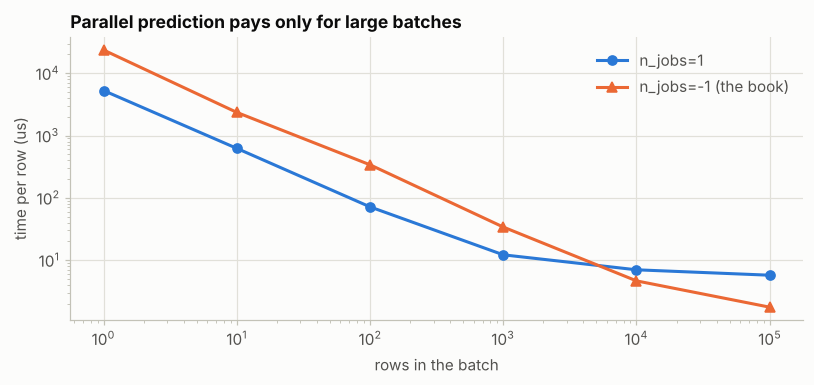

In [16]:
# EXTRA (a): prediction latency of the book's forest, n_jobs=-1 against n_jobs=1
# (timings: the numbers below change from run to run)
import copy

parallel_forest = clf
serial_forest = copy.deepcopy(clf).set_params(n_jobs=1)
batch_sizes = [1, 10, 100, 1_000, 10_000, 100_000]
rows_pool = np.random.default_rng(5).normal(size=(max(batch_sizes), 50))

t_serial = np.array([best_time(lambda m=m: serial_forest.predict(rows_pool[:m]), 30 if m <= 1_000 else 5) for m in batch_sizes])
t_parallel = np.array([best_time(lambda m=m: parallel_forest.predict(rows_pool[:m]), 30 if m <= 1_000 else 5) for m in batch_sizes])
latency = pd.DataFrame({"batch size": batch_sizes, "n_jobs=1 (ms)": t_serial * 1e3, "n_jobs=-1 (ms)": t_parallel * 1e3,
                        "ratio -1 / 1": t_parallel / t_serial, "n_jobs=1, us per row": t_serial / np.array(batch_sizes) * 1e6})
print(f"cores available to this process: {os.cpu_count()}")
print(latency.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.loglog(batch_sizes, t_serial / np.array(batch_sizes) * 1e6, marker="o", color=PALETTE[0], label="n_jobs=1")
ax.loglog(batch_sizes, t_parallel / np.array(batch_sizes) * 1e6, marker="^", color=PALETTE[1], label="n_jobs=-1 (the book)")
ax.set_xlabel("rows in the batch")
ax.set_ylabel("time per row (us)")
ax.set_title("Parallel prediction pays only for large batches")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* On this machine (4 cores), with the forest of the book (`n_jobs=-1`), predicting **1 to 100 rows takes roughly 3 to 6 times longer than with `n_jobs=1`** (about 23 ms against 5 ms for one row), and the book's own batch of **1,000 rows takes about 2.5 to 3 times longer** (about 34 ms against 12 ms). The parallel forest becomes faster somewhere between 1,000 and 10,000 rows (roughly half to two thirds of the serial time at 10,000 rows) and is **about 3 times faster at 100,000 rows** (roughly 170 to 190 ms against 570 to 600 ms). The break-even size is a property of the machine, the model and the load; the pattern (parallel prediction loses on small batches and wins on large ones, by at most about the number of cores) is general.
* The listing of the book is therefore configured against its own measurement: it times a 1,000-row batch with the setting that is slower for 1,000 rows. The hands-on exercise ("train with `n_jobs=1`, then `n_jobs=-1`, compare latency") is what extra (a) does, and its answer depends on the batch size.
* A single row costs about **5 ms** with a 100-tree forest even without threads, 50 times more than the linear model of recipe 1, because every tree has to be walked and the call has a larger fixed cost; per row, the serial forest goes from about 5 ms for one row to about 6 microseconds for 100,000 rows. For an online service the choices are fewer or shallower trees (extra (c)), `n_jobs=1` in each worker with many workers, or micro-batching.

In [17]:
# EXTRA (b): speed-up of training and of cross-validation
# (timings: the numbers below change from run to run)
fit_times = {}
for n_jobs in (1, 2, 4, -1):
    fit_times[n_jobs] = best_time(lambda n=n_jobs: RandomForestClassifier(n_estimators=100, n_jobs=n, random_state=2024).fit(X, y), 3)
cores = os.cpu_count()
speedup = {n: fit_times[1] / t for n, t in fit_times.items()}
fraction = {n: (1 - 1 / speedup[n]) / (1 - 1 / (cores if n == -1 else n)) for n in (2, 4, -1)}
print(pd.DataFrame({"n_jobs": list(fit_times), "fit (s)": list(fit_times.values()), "speed-up": list(speedup.values()),
                    "parallel fraction f (Amdahl)": [np.nan] + [fraction[n] for n in (2, 4, -1)]}).round(3).to_string(index=False))

rows = []
for forest_jobs, folds_jobs in ((1, 1), (1, -1), (-1, 1), (-1, -1)):
    t = best_time(lambda a=forest_jobs, b=folds_jobs: cross_val_score(
        RandomForestClassifier(n_estimators=50, n_jobs=a, random_state=0), X, y, cv=3, n_jobs=b), 3)
    rows.append({"forest n_jobs": forest_jobs, "cross_val_score n_jobs": folds_jobs, "time (s)": t})
cv_times = pd.DataFrame(rows)
cv_times["speed-up"] = cv_times["time (s)"].iloc[0] / cv_times["time (s)"]
print("\n3-fold cross-validation of a 50-tree forest")
print(cv_times.round(3).to_string(index=False))

 n_jobs  fit (s)  speed-up  parallel fraction f (Amdahl)
      1    0.857     1.000                           NaN
      2    0.500     1.716                         0.834
      4    0.307     2.789                         0.855
     -1    0.304     2.821                         0.861

3-fold cross-validation of a 50-tree forest
 forest n_jobs  cross_val_score n_jobs  time (s)  speed-up
             1                       1     0.842     1.000
             1                      -1     0.339     2.483
            -1                       1     0.532     1.584
            -1                      -1     0.310     2.716


**Analysis of extra (b).**

* **Training** one 100-tree forest takes about 0.85 to 0.9 s with one thread. Two threads give a speed-up of 1.6 to 1.9, four threads (and `n_jobs=-1`, which means four here) about 2.5 to 3.0, not 4. Solving Amdahl's law for the parallel fraction gives f of about 0.8 to 0.9 (noisier with two threads): roughly one tenth to one fifth of the work is serial or overhead, which caps the speed-up of any number of cores at about 5 to 10 (1/(1-f)).
* **Cross-validation** (3 folds of a 50-tree forest). Running the three folds in parallel and keeping each forest serial gives a speed-up of about **2.4 to 3.0** (at most 3, there are only 3 folds); parallelising only the forest gives about 1.7; the book's setting, both, gives about 2.6 to 2.9. Here the nested setting costs nothing extra, but the general advice stands: **parallelise one level, usually the outer one**, because on a busy machine two levels asking for all the cores compete for them.
* These numbers describe one machine and one run; the shape (sub-linear speed-up, a hard cap by the number of folds) is what transfers.

In [18]:
# EXTRA (c1): accuracy and artifact size against the number of trees
X_tr, y_tr, X_te, y_te = X[:1500], y[:1500], X[1500:], y[1500:]
tree_counts = [1, 5, 10, 25, 50, 100, 200, 400]
serving = {}
rows = []
for n_trees in tree_counts:
    forest = RandomForestClassifier(n_estimators=n_trees, n_jobs=1, random_state=2024).fit(X_tr, y_tr)
    serving[n_trees] = forest
    dump(forest, "serving.joblib")
    rows.append({"trees": n_trees, "test accuracy": forest.score(X_te, y_te), "file size (MB)": os.path.getsize("serving.joblib") / 1e6})
accuracy_size = pd.DataFrame(rows)
print(accuracy_size.round(3).to_string(index=False))

 trees  test accuracy  file size (MB)
     1          0.792           0.019
     5          0.848           0.093
    10          0.872           0.185
    25          0.862           0.467
    50          0.866           0.925
   100          0.858           1.883
   200          0.860           3.777
   400          0.868           7.602


 trees  predict 1,000 rows (ms)  ms per tree
     1                    0.393        0.393
     5                    0.881        0.176
    10                    2.260        0.226
    25                    3.283        0.131
    50                    6.030        0.121
   100                   12.106        0.121
   200                   23.739        0.119
   400                   47.447        0.119


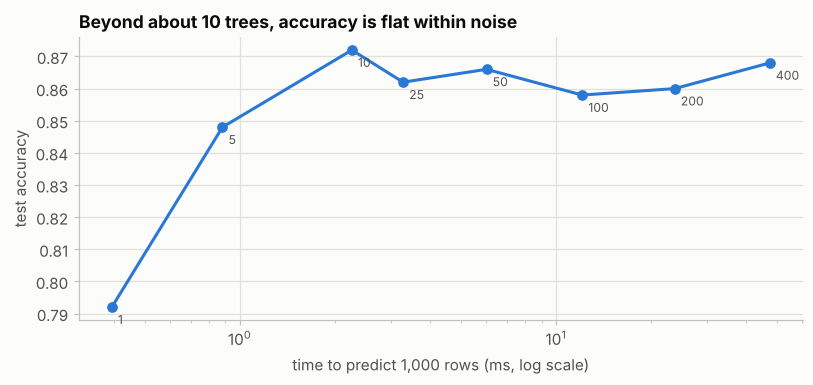

In [19]:
# EXTRA (c2): prediction time against the number of trees
# (timings: the numbers below change from run to run)
thousand = np.random.default_rng(6).normal(size=(1_000, 50))
predict_ms = np.array([best_time(lambda f=serving[n]: f.predict(thousand), 10) for n in tree_counts]) * 1e3
print(pd.DataFrame({"trees": tree_counts, "predict 1,000 rows (ms)": predict_ms,
                    "ms per tree": predict_ms / np.array(tree_counts)}).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(predict_ms, accuracy_size["test accuracy"], marker="o", color=PALETTE[0])
for n_trees, t_ms, acc in zip(tree_counts, predict_ms, accuracy_size["test accuracy"]):
    ax.annotate(str(n_trees), (t_ms, acc), textcoords="offset points", xytext=(4, -11), fontsize=8, color=INK_SOFT)
ax.set_xscale("log")
ax.set_xlabel("time to predict 1,000 rows (ms, log scale)")
ax.set_ylabel("test accuracy")
ax.set_title("Beyond about 10 trees, accuracy is flat within noise")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* **Accuracy** on 500 held-out rows: 0.792 with one tree, 0.848 with 5, **0.872 with 10**, and then between 0.858 and 0.868 for 25, 50, 100, 200 and 400 trees. The standard error of an accuracy of 0.86 on 500 rows is about 0.015, so from about 10 trees on the accuracy is **flat within the noise** of this test set: it cannot separate 10 trees from 400, and its best value (0.872, at 10 trees) is itself a draw.
* **Size and time grow in proportion to the number of trees.** The artifact goes from 0.185 MB (10 trees) to 7.6 MB (400 trees), 41 times larger, and prediction of 1,000 rows from about 1.3 to 2 ms to about 50 ms, 20 to 40 times slower: about 0.11 to 0.15 ms per tree for 25 trees and more (more for fewer trees, where the fixed overhead matters). The forest of 400 trees is 41 times larger and 20 to 40 times slower than the one of 10 trees, with no accuracy to show for it.
* The way to choose the size is the one of Chapter 12: compare candidates by cross-validation and keep the **cheapest forest within the noise of the best**. This extra uses one test set and does not replace that search; the 100 trees of the book are a default, not a measured choice.

In [20]:
# EXTRA (d): spread of the CV accuracy of the book's call over the random seed of the forest
seeded = np.array([
    cross_val_score(RandomForestClassifier(n_estimators=50, random_state=seed), X, y, cv=3, n_jobs=-1).mean()
    for seed in range(30)])
print(f"30 seeds: mean {seeded.mean():.4f}, sd {seeded.std(ddof=1):.4f}, min {seeded.min():.4f}, max {seeded.max():.4f}")
print(f"the same data with a 100-tree forest and 3 folds, one seed: {cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0), X, y, cv=3).mean():.4f}")

30 seeds: mean 0.8739, sd 0.0029, min 0.8690, max 0.8805
the same data with a 100-tree forest and 3 folds, one seed: 0.8730


**Analysis of extra (d).**

* Over 30 seeds the same cross-validation (50 trees, 3 folds, the same data) gives a mean accuracy of **0.8739** with a standard deviation of 0.0029, from 0.8690 to 0.8805. The value printed by the book's listing (about 0.875) is one draw from this distribution; another run would print 0.870 or 0.878.
* The lesson is the one of Chapter 12 in a new place: a difference in the third decimal between two runs is **noise from the randomness of the algorithm**, not information. Where a number is meant to be compared across runs (a gate, a regression test), fix `random_state`.

---
## 4. Monitoring and updating deployed models

*Book: pp. 338–341.*

### Summary

* **Recipe** — "Once your model is live, its performance will degrade over time due to changes in input data distributions (drift) or external conditions." This is where the "CT" of CI/CD/CT comes in: besides building and releasing software, an ML deployment needs *continuous training* to monitor and manage models as they degrade. The recipe shows how to monitor a deployed model, detect drift, and update the model.
* **Getting ready** — `X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)` for the initial training and `X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)` for the "streaming" data, both cut into four pieces with `np.array_split`.
* **How to do it** — (1) train `SGDClassifier(loss="log_loss", random_state=2024, warm_start=True)` with `partial_fit` on the initial data; (2) predict each incoming batch and store its accuracy in `batch_scores`; (3) "trigger retraining when accuracy drops below the threshold (e.g., < 0.8)" by calling `clf.partial_fit(X_pub, y_pub)`; (4) plot the accuracy of each batch (Figure 13.1).
* **The book's reading of Figure 13.1** — "Although there is a dip initially with accuracy in the first batch, it's to be expected that this could go either way. We'd expect the accuracy to increase over each consecutive batch, which appears to be the case. ... Although we are only simulating three batches, we can see that the general trend is going up."
* **How it works** — for models that support `partial_fit` and `warm_start`, such as `SGDClassifier`, "you can continue training as new data arrives. Monitoring batch accuracy provides a simple drift detector. If performance drops below a defined threshold, retraining the model—or updating it with streaming data—can restore accuracy."
* **There's more** — more sophisticated drift detection monitors distribution statistics or embeds the inputs to compute the KL divergence or statistical tests; retraining can be automated with control systems that have alerting and rollback.
* **Hands-on exercises** — simulate streaming batches, train an incremental model, track its performance over time, visualize the trend, and automate retraining when accuracy falls below a chosen threshold.

### Theory

**What can change after deployment.** Write the data-generating process as $P(X, Y) = P(X)\,P(Y \mid X)$. A deployed model can degrade for three different reasons.

| Kind of change | What moves | Example | Does it hurt a correct model? |
|---|---|---|---|
| **Covariate shift** | $P(X)$ changes, $P(Y \mid X)$ does not | a new customer segment, a sensor recalibrated | only where the model extrapolates or is misspecified |
| **Prior (label) shift** | $P(Y)$ changes | fraud becomes more frequent | calibration and thresholds, not the ranking |
| **Concept drift** (real drift) | $P(Y \mid X)$ changes | what makes a customer churn changes | usually: the learned rule is no longer right |

Gama et al. (2014) add the *shape* of the change in time: abrupt, gradual, incremental, recurring. Concept drift is the change that most directly invalidates the learned rule, and it is invisible to any monitor that looks at the inputs alone.

**What to monitor.**

* *Performance metrics* (accuracy, $F_1$, error of a regression) need the true label, which often arrives late or never (a loan defaults months later). The book's batch accuracy assumes labels are available for each batch.
* *Input statistics*: per-feature means, ranges, missing-value rates, and two-sample tests between a reference window and the current batch: the Kolmogorov–Smirnov statistic for numerical features, a chi-square test for categorical ones, or the **population stability index**, $\mathrm{PSI} = \sum_b (p_b - q_b)\ln(p_b/q_b)$ over bins $b$ of the reference ($p$) and current ($q$) distributions, for which a PSI above 0.1 to 0.25 is a common rule of thumb in credit scoring. With many features, tests must be corrected for multiplicity (Bonferroni). Rabanser, Günnemann and Lipton (2019) compared shift detectors and found that a two-sample test applied to a low-dimensional representation of the data (for example the model's own soft predictions, "black-box shift detection") worked best, and that several univariate tests combined with a Bonferroni correction performed about as well as multivariate tests.
* *Output statistics*: the share of predicted positives and the distribution of predicted probabilities; these need no labels and change when either $P(X)$ or the model's behavior changes.
* *Sequential detectors* decide online when an error rate has changed: DDM and Page–Hinkley monitor the error rate; ADWIN (Bifet and Gavaldà, 2007) keeps a window of adaptive length and shrinks it when two sub-windows have different means, with guarantees on false positives and false negatives.

**A threshold on batch accuracy is a hypothesis test.** If the true accuracy of the model is $p$ and the batch has $m$ labelled rows, the batch accuracy has standard deviation $\sqrt{p(1-p)/m}$ (0.05 for $p = 0.84$ and $m = 50$). The rule "alarm if accuracy $< 0.8$" then fires by chance with probability $P(\mathrm{Bin}(m, p) < 0.8\,m)$, which is large when $p$ is close to the threshold or $m$ is small (extra (b)). The threshold must come from the *distribution of batch accuracy under normal operation* (for example the baseline minus three standard errors), not from a round number, and the batch size sets how small a degradation can be seen.

**Online learning and `partial_fit`.** Stochastic gradient descent updates the weights from a few samples at a time,
$$w_{t+1} = w_t - \eta_t \big(\nabla_w L(w_t; x_t, y_t) + \alpha\, w_t\big),$$
so a model can learn from a stream without storing it (Bottou, 2010). In scikit-learn, `SGDClassifier.partial_fit(X, y)` makes **one pass** over the data it is given and then returns, keeping the weights and a counter `t_` of updates made. With the default `learning_rate="optimal"` the step is $\eta_t = 1/(\alpha\,(t_0 + t))$, which **decays with the number of updates seen** since the model was created: a model that has processed many samples barely moves for new ones, so it adapts slowly to drift. `learning_rate="constant"` (with `eta0`) keeps adapting at a noisier steady pace. `warm_start=True` matters for repeated calls of `fit` (the next `fit` starts from the previous weights); `partial_fit` always continues from the current weights, so the `warm_start=True` of the book's listing changes nothing (extra (e)). Only some estimators have `partial_fit` (`SGDClassifier`, `SGDRegressor`, `MultinomialNB`, `Perceptron`, `MiniBatchKMeans`, ...); a forest or a gradient-boosting model must be refitted.

**Policies for updating.** (i) *Never update* (frozen). (ii) *Update when an alarm fires*, on the alarming batch or on a window of recent batches. (iii) *Update continuously*, on every batch, after predicting it. (iv) *Retrain periodically* on a sliding window or on all the data. Evaluating a continuously updated model needs care: the standard protocol for streams is **prequential** (test-then-train) evaluation, where each batch is first used to measure the current model and only then to update it (Gama et al., 2014); measuring a model on the data it was just trained on gives a training score. The book's listing follows the test-then-train order but never re-evaluates the model after retraining.

**Practical issues.** Feedback loops (the model's decisions change the data it will see; Sculley et al., 2015), delayed labels (use input and output monitors in the meantime), and rollbacks (keep the previous model, recipe 5) belong to every real monitoring design.

### Book code

The book's two listings: the simulated data (p. 339) and the monitoring loop with its plot (pp. 339–340). Both are the book's code unchanged; every random call has an explicit `random_state`.

In [21]:
# BOOK CODE (p. 339): load the libraries and simulate the initial training data and the stream
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

# Simulate initial training and streaming data
X_train, y_train = make_classification(
    n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(
    n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

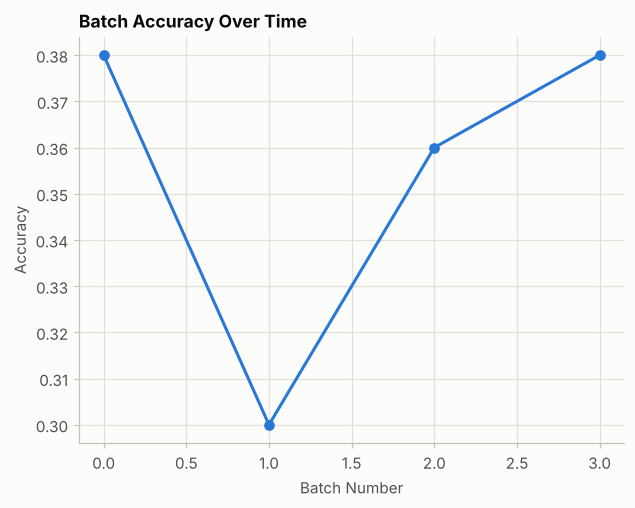

In [22]:
# BOOK CODE (pp. 339-340): train incrementally, monitor each batch, retrain below the threshold, plot
# Train an incremental SGDClassifier on initial data
clf = SGDClassifier(
    loss="log_loss", random_state=2024, warm_start=True)
clf.partial_fit(
    X_train, y_train, classes=np.unique(y_train))

# Monitor each incoming batch
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))

# Trigger retraining when accuracy drops below threshold (e.g. < 0.8)
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)

# Plot batch-by-batch accuracy
plt.plot(batch_scores, marker="o")
plt.title("Batch Accuracy Over Time")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

**Output analysis.**

* The first listing prints nothing. The second prints nothing either and draws **Figure 13.1**: four points, the accuracy of the model on each of the four batches, which are (extra (a)) **0.38, 0.30, 0.36 and 0.38**. Because the minimum is below 0.8, the retraining step ran.
* This does not match the book's reading of the figure. The text speaks of **three batches**; the code makes **four**. The text says that after a dip in the first batch "we'd expect the accuracy to increase over each consecutive batch, which appears to be the case", and that "the general trend is going up"; the plotted values go 0.38, 0.30, 0.36, 0.38, so the last batch only comes back to the level of the first. A batch of 50 rows has a standard error of about 0.07, so none of these differences is meaningful.
* The more important point is the level: **all four accuracies are below 0.5**, worse than a coin flip. A model with an accuracy of 0.89 on its training data that scores 0.38 on later batches is not "drifting"; extra (a) shows what the stream really is.

### Extra experiments

**(a) What is the book's stream?** The cell rebuilds the book's initial model and checks four things: the accuracies in `batch_scores`; the accuracy of the same model on **199 other problems** produced by `make_classification` with other seeds (2026 to 2224), to see whether 2025 is special; the accuracy on a stream that really comes from the *same* problem (one `make_classification` call of 700 samples, the first 500 for training and the last 200 cut into four batches); and what the book's retraining step does to the accuracy on the original training data and on the stream. The figure shows the distribution over the 200 problems.

accuracy of the book's model on its four batches: [0.38, 0.3, 0.36, 0.38]
accuracy on the training data X_train: 0.892

accuracy on 199 other make_classification problems (seeds 2026-2224): mean 0.497, sd 0.153, min 0.160, max 0.855
share below 0.5: 55%; share at or above 0.8: 2.5%
the book's stream (seed 2025): 0.355, at rank 34 of 200 from the bottom (itself included)

stream from the same problem (one call, 500 + 200 rows): batch accuracies [0.8, 0.84, 0.8, 0.9], overall 0.835

the book's retraining step: accuracy on X_train 0.892 -> 0.544; on the stream 0.355 -> 0.775 (the stream rows were the training data of that step)


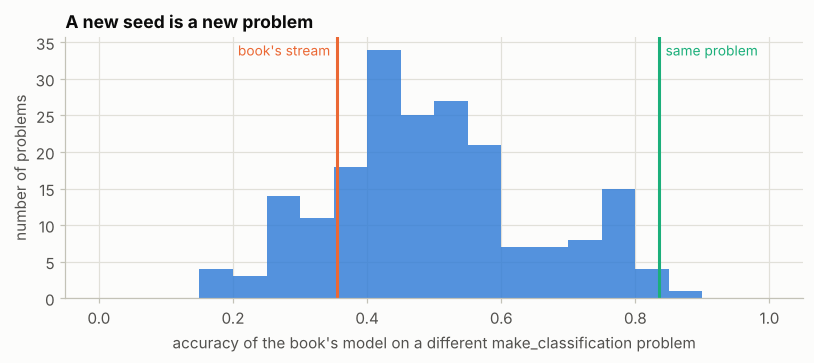

In [23]:
# EXTRA (a): the book's stream is another problem, not a drifted version of the first one
import copy
from scipy import stats

book_model = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True).partial_fit(X_train, y_train, classes=np.unique(y_train))
print("accuracy of the book's model on its four batches:", [round(float(s), 3) for s in batch_scores])
print(f"accuracy on the training data X_train: {book_model.score(X_train, y_train):.3f}")

other_problems = np.array([
    book_model.score(*make_classification(n_samples=200, n_features=10, random_state=seed)) for seed in range(2026, 2225)])
print(f"\naccuracy on 199 other make_classification problems (seeds 2026-2224): mean {other_problems.mean():.3f}, "
      f"sd {other_problems.std():.3f}, min {other_problems.min():.3f}, max {other_problems.max():.3f}")
print(f"share below 0.5: {np.mean(other_problems < 0.5):.0%}; share at or above 0.8: {np.mean(other_problems >= 0.8):.1%}")
print(f"the book's stream (seed 2025): {book_model.score(X_pub, y_pub):.3f}, at rank {np.sum(other_problems <= book_model.score(X_pub, y_pub)) + 1} of 200 from the bottom (itself included)")

X_one, y_one = make_classification(n_samples=700, n_features=10, random_state=2024)
same_problem = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True).partial_fit(X_one[:500], y_one[:500], classes=[0, 1])
coherent = [float(np.mean(same_problem.predict(xb) == yb)) for xb, yb in zip(np.array_split(X_one[500:], 4), np.array_split(y_one[500:], 4))]
print(f"\nstream from the same problem (one call, 500 + 200 rows): batch accuracies {[round(a, 3) for a in coherent]}, "
      f"overall {same_problem.score(X_one[500:], y_one[500:]):.3f}")

retrained = copy.deepcopy(book_model).partial_fit(X_pub, y_pub)
print(f"\nthe book's retraining step: accuracy on X_train {book_model.score(X_train, y_train):.3f} -> {retrained.score(X_train, y_train):.3f}; "
      f"on the stream {book_model.score(X_pub, y_pub):.3f} -> {retrained.score(X_pub, y_pub):.3f} (the stream rows were the training data of that step)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(other_problems, bins=np.linspace(0, 1, 21), color=PALETTE[0], alpha=0.8)
ax.axvline(np.mean(batch_scores), color=PALETTE[1], lw=2)
ax.axvline(same_problem.score(X_one[500:], y_one[500:]), color=PALETTE[2], lw=2)
ax.text(np.mean(batch_scores) - 0.01, ax.get_ylim()[1] * 0.93, "book's stream", color=PALETTE[1], ha="right", fontsize=9)
ax.text(same_problem.score(X_one[500:], y_one[500:]) + 0.01, ax.get_ylim()[1] * 0.93, "same problem", color=PALETTE[2], ha="left", fontsize=9)
ax.set_xlabel("accuracy of the book's model on a different make_classification problem")
ax.set_ylabel("number of problems")
ax.set_title("A new seed is a new problem")
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The book's model scores **0.892 on its training data** and **0.355 on the whole stream** (the mean of the four batch accuracies).
* On **199 other problems** built by `make_classification` with seeds 2026 to 2224, the same model scores on average **0.497** (standard deviation 0.153, from 0.160 to 0.855): 55% of the problems give an accuracy below 0.5 and only 2.5% reach 0.8. The stream of the book (seed 2025, 0.355) is an ordinary draw from that distribution: rank 34 of 200 from the bottom, within one standard deviation of the mean. A different `random_state` of `make_classification` draws other class centres and other linear mixtures of the features: it is **another problem, not the same problem after a drift**. The accuracy below 0.5 means that the learned rule is partly *reversed* for that problem, which no model that "learns from the stream" can fix by a small update.
* A stream that really comes from the training population (one call of 700 samples, the first 500 for training and the last 200 cut into four batches) gives batch accuracies of **0.80, 0.84, 0.80 and 0.90** and an overall accuracy of 0.835. That is what a deployed model that is working looks like; the book's 0.8 threshold sits only about 3.5 points below that accuracy, so with 50-row batches it would still raise a false alarm on about 19% of the batches (extra (b)).
* The book's retraining step moves the model towards the foreign problem: its accuracy on the original training data **falls from 0.892 to 0.544**, and its accuracy on the stream rises from 0.355 to 0.775, but those are the rows that the update just used (a training score). Nothing in the listing measures the retrained model on new batches or on the old regime; a real update must be validated on fresh data, and on the old data if it can still occur.

**(b) How often does a threshold rule cry wolf?** For a model whose true accuracy is $p$, the table gives the probability that a batch of $m$ labelled rows has an accuracy below the book's threshold of 0.8, computed exactly from the binomial distribution.

In [24]:
# EXTRA (b): probability that "batch accuracy < 0.8" fires, by true accuracy and batch size
true_accuracy = [0.95, 0.90, 0.88, 0.85, 0.835, 0.80, 0.75, 0.70]
alarm = pd.DataFrame({
    f"batch of {m}": [stats.binom.cdf(4 * m // 5 - 1, m, p) for p in true_accuracy] for m in (50, 200, 1_000)
}, index=pd.Index(true_accuracy, name="true accuracy"))
print("probability that a batch triggers the alarm")
print(alarm.round(3).to_string())

probability that a batch triggers the alarm
               batch of 50  batch of 200  batch of 1000
true accuracy                                          
0.950                0.000         0.000          0.000
0.900                0.009         0.000          0.000
0.880                0.032         0.000          0.000
0.850                0.120         0.022          0.000
0.835                0.192         0.079          0.002
0.800                0.416         0.458          0.481
0.750                0.738         0.942          1.000
0.700                0.921         0.999          1.000


**Analysis of extra (b).**

* A model whose true accuracy is **0.88** triggers the alarm "accuracy below 0.8" in 3.2% of batches of 50 rows; at **0.85** it does so in 12%; at **0.835**, the accuracy of the coherent stream, in **19% of batches of 50 rows**, 7.9% of batches of 200 and 0.2% of batches of 1,000. With the book's 50-row batches, almost one batch in five would raise a false alarm on a healthy model.
* A model exactly at 0.80 alarms about half the time whatever the batch size (0.42 to 0.48): the threshold is a coin flip when the model sits on it. A model that has really degraded to 0.75 alarms in 74% of batches of 50, 94% of batches of 200 and every batch of 1,000: **larger batches make the alarm both more specific and more sensitive**, at the price of more labelled rows and a slower reaction.
* So the threshold of 0.8 and the batch size cannot be chosen independently. A defensible rule takes the accuracy measured in normal operation, subtracts a multiple of its standard error for the chosen batch size, and uses the result as the alarm level.

**(c) Five ways of updating, under a drift that is really there.** A stream is generated from a linear rule $y = \mathbb{1}[w_t \cdot x + 0.3\,\varepsilon > 0]$ in 10 dimensions (8 informative features, 2 irrelevant). The weight vector $w_t$ stays at $w_0$ for 10 batches of 100 rows, **rotates gradually by 90 degrees** during batches 10 to 29 and stays there for 10 more batches. Every policy starts from a model fitted on 500 rows of the initial concept and then follows the stream by **test-then-train**: the batch is first scored, then the policy decides whether to update. The table averages 50 independent streams; the figure shows four of the policies.

                                 policy  mean accuracy  batches 0-9  batches 10-29 (drift)  batches 30-39  alarms per stream  alarms in batches 0-9
                 frozen (never updated)          0.696        0.859                  0.714          0.497              24.18                   0.54
        alarm: partial_fit on the batch          0.849        0.864                  0.839          0.855               4.44                   0.24
               every batch: partial_fit          0.867        0.863                  0.868          0.869               1.36                   0.34
every batch: partial_fit, constant rate          0.890        0.897                  0.883          0.895               0.18                   0.00
     alarm: refit on the last 5 batches          0.867        0.900                  0.850          0.868               3.54                   0.02


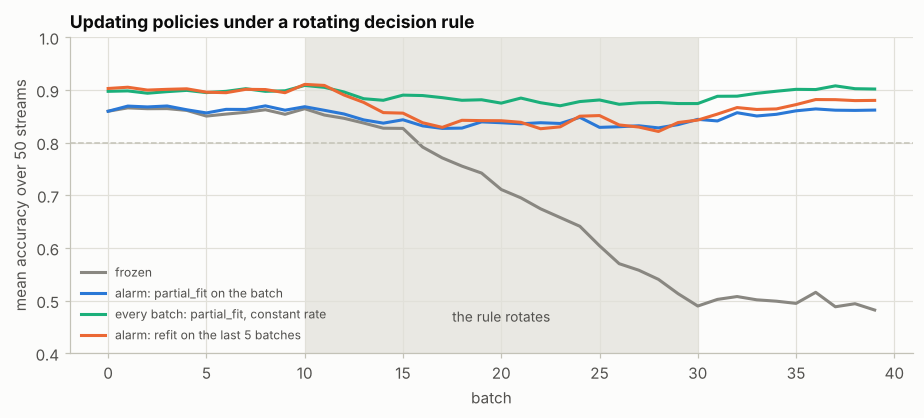

In [25]:
# EXTRA (c): update policies under a gradual concept drift (prequential evaluation, 50 streams)
from sklearn.linear_model import LogisticRegression

n_features, n_informative, n_batches, batch_rows, noise = 10, 8, 40, 100, 0.3
setup_rng = np.random.default_rng(7)
w_start = np.r_[setup_rng.normal(size=n_informative), np.zeros(n_features - n_informative)]
w_start /= np.linalg.norm(w_start)
w_end = np.r_[setup_rng.normal(size=n_informative), np.zeros(n_features - n_informative)]
w_end -= (w_end @ w_start) * w_start
w_end /= np.linalg.norm(w_end)


def weights_at(t):
    angle = np.clip((t - 10) / 20, 0, 1) * (np.pi / 2)
    return np.cos(angle) * w_start + np.sin(angle) * w_end


def draw_batch(t, rows, rng):
    features = rng.normal(size=(rows, n_features))
    labels = (features @ weights_at(t) + noise * rng.normal(size=rows) > 0).astype(int)
    return features, labels


def follow_stream(policy, seed, **sgd_options):
    rng = np.random.default_rng(seed)
    X0, y0 = draw_batch(0, 500, rng)
    if policy == "window refit":
        model = LogisticRegression().fit(X0, y0)
    else:
        model = SGDClassifier(loss="log_loss", random_state=0, **sgd_options).partial_fit(X0, y0, classes=[0, 1])
    recent, accuracy, alarms = [], [], []
    for t in range(n_batches):
        Xb, yb = draw_batch(t, batch_rows, rng)
        acc = np.mean(model.predict(Xb) == yb)  # test ...
        accuracy.append(acc)
        alarms.append(acc < 0.8)
        if policy == "alarm: partial_fit on the batch" and acc < 0.8:  # ... then train
            model.partial_fit(Xb, yb)
        elif policy == "every batch: partial_fit":
            model.partial_fit(Xb, yb)
        elif policy == "window refit":
            recent = (recent + [(Xb, yb)])[-5:]
            if acc < 0.8:
                model = LogisticRegression().fit(np.vstack([r[0] for r in recent]), np.concatenate([r[1] for r in recent]))
    return np.array(accuracy), np.array(alarms)


policies = {
    "frozen (never updated)": ("frozen", {}),
    "alarm: partial_fit on the batch": ("alarm: partial_fit on the batch", {}),
    "every batch: partial_fit": ("every batch: partial_fit", {}),
    "every batch: partial_fit, constant rate": ("every batch: partial_fit", dict(learning_rate="constant", eta0=0.05)),
    "alarm: refit on the last 5 batches": ("window refit", {}),
}
curves, rows = {}, []
for label, (policy, options) in policies.items():
    runs = [follow_stream(policy, 100 + s, **options) for s in range(50)]
    acc = np.array([r[0] for r in runs])
    alarms = np.array([r[1] for r in runs])
    curves[label] = acc.mean(0)
    rows.append({"policy": label, "mean accuracy": acc.mean(), "batches 0-9": acc[:, :10].mean(), "batches 10-29 (drift)": acc[:, 10:30].mean(),
                 "batches 30-39": acc[:, 30:].mean(), "alarms per stream": alarms.sum(1).mean(), "alarms in batches 0-9": alarms[:, :10].sum(1).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.axvspan(10, 30, color=GRID, alpha=0.7, lw=0)
ax.text(20, 0.46, "the rule rotates", ha="center", fontsize=9, color=INK_SOFT)
ax.plot(curves["frozen (never updated)"], color=MUTED, label="frozen")
ax.plot(curves["alarm: partial_fit on the batch"], color=PALETTE[0], label="alarm: partial_fit on the batch")
ax.plot(curves["every batch: partial_fit, constant rate"], color=PALETTE[2], label="every batch: partial_fit, constant rate")
ax.plot(curves["alarm: refit on the last 5 batches"], color=PALETTE[1], label="alarm: refit on the last 5 batches")
ax.axhline(0.8, color=AXIS, ls="--", lw=1)
ax.set_xlabel("batch")
ax.set_ylabel("mean accuracy over 50 streams")
ax.set_ylim(0.4, 1.0)
ax.set_title("Updating policies under a rotating decision rule")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* **Without updates the model is lost.** The frozen model scores 0.859 before the drift, 0.714 during it, and **0.497 after it** (chance: the rule has rotated by 90 degrees); it would raise an alarm on 24 of the 40 batches.
* **Every update policy recovers**, with different quality. By mean accuracy over the 40 batches: updating on every batch with a constant learning rate **0.890**; refitting on the last 5 batches after an alarm 0.867 (a different learner, a logistic regression refitted to convergence, which also starts higher before the drift); updating on every batch with the default decaying rate 0.867; updating only on the alarming batch 0.849, a per-batch version of the book's rule (the book retrains once, on all four batches); frozen 0.696. The best policy, in the last 10 batches, holds 0.895.
* The per-batch alarm rule is the weakest of the updating policies: it learns only from batches that already scored below 0.8, so it reacts late, while continuous updating adapts as soon as the rule moves. The constant-rate model also starts better (0.897 against 0.863 before the drift), so this experiment does **not isolate** the effect of the decaying `"optimal"` rate: in theory the decay slows adaptation (extra (e)), but the table cannot attribute the gap to it.
* The first ten batches show what the models are worth *before* any drift: the refitted logistic regression reaches 0.900, the stochastic gradient models 0.86 to 0.90 (one pass over 500 rows has not converged). The alarms in these batches (0.54 per stream for the frozen model, 0.02 for the refit) are **false alarms** at a threshold only about 1.5 to 1.7 standard errors below the accuracy of the SGD models: the same effect as in extra (b).
* This is a toy with a linear rule, 100-row batches and untuned constants; the ranking will not transfer exactly. What transfers is the structure: a fixed model fails under concept drift, update rules differ widely, and a model that follows the stream must be evaluated test-then-train.

In [26]:
# EXTRA (d): label-free KS alarms against the accuracy of a fixed model
def ks_stream(kind, seed):
    rng = np.random.default_rng(seed)
    X0, y0 = draw_batch(0, 500, rng)
    reference, _ = draw_batch(0, 1_000, rng)
    model = LogisticRegression().fit(X0, y0)
    strongest = int(np.argmax(np.abs(w_start)))
    accuracy, ks_alarm = [], []
    for t in range(40):
        features = rng.normal(size=(200, n_features))
        weights = w_end if (kind == "concept drift" and t >= 20) else w_start
        if kind == "irrelevant feature shifts" and t >= 20:
            features[:, n_features - 1] += 1.0
        if kind == "relevant feature shifts" and t >= 20:
            features[:, strongest] += 1.5
        labels = (features @ weights + noise * rng.normal(size=200) > 0).astype(int)
        accuracy.append(np.mean(model.predict(features) == labels))
        p_values = [stats.ks_2samp(reference[:, j], features[:, j]).pvalue for j in range(n_features)]
        ks_alarm.append(min(p_values) < 0.05 / n_features)
    return np.array(accuracy), np.array(ks_alarm)


rows = []
for kind in ("nothing changes", "irrelevant feature shifts", "relevant feature shifts", "concept drift"):
    runs = [ks_stream(kind, 500 + s) for s in range(30)]
    acc = np.array([r[0] for r in runs])
    alarm = np.array([r[1] for r in runs])
    rows.append({"situation": kind, "accuracy before": acc[:, :20].mean(), "accuracy after": acc[:, 20:].mean(),
                 "KS alarm rate before": alarm[:, :20].mean(), "KS alarm rate after": alarm[:, 20:].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                situation  accuracy before  accuracy after  KS alarm rate before  KS alarm rate after
          nothing changes            0.902           0.903                 0.047                0.063
irrelevant feature shifts            0.902           0.903                 0.047                1.000
  relevant feature shifts            0.902           0.940                 0.047                1.000
            concept drift            0.902           0.499                 0.047                0.063


**Analysis of extra (d).**

* **Nothing changes**: the accuracy stays at 0.90 and the KS monitor raises an alarm in 4.7% of the batches before and 6.3% after, close to the 5% that the Bonferroni-corrected test allows per batch.
* **An irrelevant feature shifts by one standard deviation**: the accuracy does not move (0.902 to 0.903) and the monitor alarms in **100%** of the batches. A distribution alarm without any harm.
* **A relevant feature shifts by 1.5 standard deviations**: the monitor alarms in 100% of the batches, and the accuracy **rises** from 0.902 to 0.940. The model is a correctly specified linear rule, and the shift moves the whole distribution of the score $w \cdot x$ away from the decision boundary, so fewer points lie close to it. Covariate shift hurts only where the model extrapolates badly or is misspecified.
* **Concept drift**: the accuracy falls from 0.902 to **0.499** (chance) and the monitor alarms in 6.3% of the batches, which is the false-alarm level: it is **silent**, because the distribution of the inputs has not changed.
* In three of the four situations the input monitor and the accuracy tell different stories. An input monitor is valuable when labels arrive late, as an early warning that something changed; it cannot say whether the change matters, and it cannot see concept drift at all. Accuracy on labelled batches is the only direct measure of harm; use both.

**(e) What `partial_fit` does with `warm_start` and with the update counter.** Two models are trained with identical calls, one with `warm_start=True` (the book) and one with `warm_start=False`; the cell compares their coefficients and shows the counter `t_` that drives the `"optimal"` learning rate.

In [27]:
# EXTRA (e): warm_start has no effect on partial_fit; t_ counts the updates
X_a, y_a = X_train, y_train
models = {flag: SGDClassifier(loss="log_loss", random_state=2024, warm_start=flag) for flag in (True, False)}
for flag, model in models.items():
    model.partial_fit(X_a, y_a, classes=[0, 1])
    for xb, yb in zip(stream_batches, stream_labels):
        model.partial_fit(xb, yb)
print("coefficients identical with warm_start=True and False after 5 calls of partial_fit:",
      np.array_equal(models[True].coef_, models[False].coef_))

counter = SGDClassifier(loss="log_loss", random_state=2024)
counter.partial_fit(X_a, y_a, classes=[0, 1])
print(f"t_ after the first call (500 rows): {counter.t_:.0f}")
for i, (xb, yb) in enumerate(zip(stream_batches, stream_labels), start=1):
    counter.partial_fit(xb, yb)
    print(f"t_ after batch {i} ({len(xb)} rows): {counter.t_:.0f}")

coefficients identical with warm_start=True and False after 5 calls of partial_fit: True
t_ after the first call (500 rows): 501
t_ after batch 1 (50 rows): 551
t_ after batch 2 (50 rows): 601
t_ after batch 3 (50 rows): 651
t_ after batch 4 (50 rows): 701


**Analysis of extra (e).**

* After five calls of `partial_fit` with identical data, the coefficients of the model with `warm_start=True` (the book) and with `warm_start=False` are **exactly equal**: `partial_fit` always continues from the current weights, so the argument is irrelevant for it. `warm_start` changes the behavior of `fit`, not of `partial_fit`.
* The counter `t_` is 501 after the first call on 500 rows and grows by 50 with every batch (551, 601, 651, 701): it counts the samples seen plus one. With the default `learning_rate="optimal"` the step size is a decreasing function of `t_`, so the longer the model runs, the less each new batch moves it. In theory this slows the adaptation of a model that has been updated for a long time (extra (c) compares update policies but does not isolate this effect).

---
## 5. Managing the model life cycle

*Book: pp. 341–343.*

### Summary

* **Recipe** — "Managing a model's life cycle ensures it remains reliable, reproducible, and maintainable over time. Building ML models is never a set it and forget it procedure. All models deteriorate over time and become less effective at making predictions for a variety of reasons (i.e., data changes, prediction targets change, etc.)." The recipe covers versioning, reproducibility, document control and consistency between training and serving environments.
* **Getting ready** — a `RandomForestClassifier(n_estimators=50, random_state=2024)` fitted on `make_classification(n_samples=800, n_features=20, random_state=2024)`.
* **How to do it** — (1) save the artifact with a versioned file name, `rf_v1.0.joblib`; (2) save a metadata dictionary `{"version": version, "sklearn": "1.3.2", "numpy": str(np.__version__)}` as JSON; (3) capture a validation snapshot, `Xv, yv = load_iris(return_X_y=True)`, `accuracy_score(yv, clf.predict(Xv))`, written to `rf_v1.0_val.txt`. The book calls this "a very simplified version of metadata's use case" and mentions MLOps tools for "far more robust documentation".
* **How it works** — "The scikit-learn roadmap recommends snapshotting not only the model but also the code, library versions, and a small validation set with its predicted outputs, to ensure the model can be validated after future upgrades or porting. Storing metadata with each artifact helps trace back issues, roll back to previous versions, and ensure reproducibility."
* **There's more** — model registries such as MLflow and BentoML "offer automation for artifact storage, metadata tracking, and rollback capabilities"; snapshotting dependencies and validation outputs remains a best practice even with such tools.
* **Hands-on exercises** — version the saved model as an artifact, document its metadata, run validation checks after deployment and plan rollbacks: train, assign a semantic version, save the model, the metadata and a validation snapshot, "simulate a scikit-learn upgrade or change, attempt to load the artifact, and validate predictions", and compare the results.

### Theory

**Why a life cycle.** A model is not a file but a *process*: data are collected, a model is trained, evaluated, released, observed, and eventually replaced. At each step someone will later ask "which model made this prediction, trained on what, with which code, and how good was it then?" Without records, the questions cannot be answered, a bad release cannot be undone, and a result cannot be reproduced. Kreuzberger et al. (2023) put *versioning* (of data, model and code), *reproducibility* and *metadata tracking* among the nine principles of MLOps.

**What a complete record contains.** The scikit-learn documentation (section "Security and maintainability limitations") lists what to save next to a pickled model so that a similar model can be rebuilt with future versions: a reference to an immutable snapshot of the **training data**, the **source code** that produced the model, the **versions** of scikit-learn and its dependencies, and the **cross-validation score** obtained on the training data (so that the retrained model can be checked to be in the same range). To that list this recipe adds: the hyperparameters and random seeds, a **checksum** of the artifact, the **evaluation on data the model never saw**, and a **validation snapshot** ("golden set"): a small fixed set of inputs together with the outputs the released model gave for them. A model card (Mitchell et al., 2019) is the human-readable version of the same record: intended use, evaluation data and metrics, caveats.

**The validation snapshot.** After an upgrade of the library, a port to another machine or a change in serving code, replaying the snapshot answers a simple question: *does the loaded model behave as the released one did?* For deterministic models the probabilities should match to numerical precision (`np.allclose`); a mismatch is a failed release. A snapshot is useful only if its inputs have **not** been used to fit the model when it is also meant to report performance, and it must be stored with the version of the artifact it belongs to.

**Versioning.** A semantic scheme `MAJOR.MINOR.PATCH` works for models: increase MAJOR when the input schema or the meaning of the output changes (consumers must adapt), MINOR when the model is retrained or improved with the same interface, PATCH for fixes that leave predictions unchanged. The version must appear in the file name, in the metadata and in every prediction log.

**Registries and release strategies.** A registry stores versions of artifacts with their metadata and a *stage* (staging, production, archived) and offers a pointer "current production model" that can be moved, which is what makes **rollback** a one-line operation. New versions are usually released gradually: *shadow* (the new model scores live traffic but its output is not used), *canary* (a small share of traffic), *A/B test* (a comparison of outcomes), *blue-green* (two full environments and a switch). The previous version stays available until the new one has proved itself.

**Compatibility across library versions.** scikit-learn stores `_sklearn_version` in the state of every estimator and emits `InconsistentVersionWarning` when the version at load time differs from the version at save time. The warning is advisory: loading may succeed and predict correctly, silently predict differently, or fail. Because the documentation calls cross-version loading unsupported, the safe procedure after an upgrade is to **retrain from the recorded recipe** and validate the new artifact against the snapshot.

**Reproducibility.** Training is reproducible when the data, the code, the library versions and every source of randomness are fixed: `random_state` for each estimator and splitter, a seed for any global generator the code uses. For scikit-learn estimators with a fixed `random_state`, results do not depend on `n_jobs`. Byte-identical artifacts are a stricter requirement, because hyperparameters that do not affect predictions (such as `n_jobs`) are stored in the file.

### Book code

The book's two listings: the model (pp. 341–342) and the saving of the artifact, the metadata and the validation snapshot (p. 342). **One line differs from the book's text.** The book's third step loads the iris data as the validation set, which cannot work with a model trained on 20 features (extra (a) runs the book's line and shows the error). The listing below follows the **official notebook of the book's repository**, which uses `train_test_split` on the data of the previous cell. The files are written to the scratch directory.

In [28]:
# BOOK CODE (pp. 341-342): load the libraries, train a model and simulate a versioning environment
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from joblib import dump
import json

# Train a model and simulate versioning environment
X, y = make_classification(
    n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(
    n_estimators=50, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_estimators=50, random_state=2024)

In [29]:
# BOOK CODE (p. 342): save the artifact, the metadata and a validation snapshot
# (the validation set follows the official notebook: the book's load_iris line fails, see extra (a))
from sklearn.model_selection import train_test_split

# Use X and y from the previous cell (already defined and used to train clf)
Xv, _, yv, _ = train_test_split(X, y, test_size=0.8, random_state=2024)

# Save the model artifact with versioned filename
version = "v1.0"
dump(clf, f"rf_{version}.joblib")

# Save metadata about training environment
meta = {"version": version, "sklearn": "1.3.2", "numpy": str(np.__version__)}
with open(f"rf_{version}_metadata.json", "w") as f:
    json.dump(meta, f)

# Capture validation set performance snapshot
yv_pred = clf.predict(Xv)
val_acc = accuracy_score(yv, yv_pred)
with open(f"rf_{version}_val.txt", "w") as f:
    f.write(f"{val_acc:.4f}")

**Output analysis.**

* The first listing displays the fitted forest. The second prints nothing and writes **three files**, `rf_v1.0.joblib`, `rf_v1.0_metadata.json` and `rf_v1.0_val.txt` (extra (a) reads them back).
* Reading the second listing as a record shows three problems. (1) The metadata hard-codes `"sklearn": "1.3.2"`, while the library that wrote the artifact is 1.9.1 (extra (a) prints both): the one field meant to protect against version mismatches is wrong from the start. (2) The validation set of the official notebook consists of rows that were **used to fit the model**, so the accuracy it stores is the training accuracy (1.0000). (3) The line in the book's text, which loads the iris data, fails with an error (extra (a)).

### Extra experiments

**(a) What the book's validation line does, and what the saved numbers say.** The cell runs the book's literal line (`load_iris`) against the model, reads back the three files written above, and measures the overlap between the "validation" rows of the official version and the rows the model was fitted on. It then computes what an honest snapshot would hold: a forest fitted on 800 rows and scored on 200 rows that it never saw.

In [30]:
# EXTRA (a): the book's validation line, the saved files, and an honest hold-out
try:
    Xv_iris, yv_iris = load_iris(return_X_y=True)
    clf.predict(Xv_iris)
except ValueError as error:
    print("the book's line, clf.predict(iris):", error)
print("iris has", Xv_iris.shape[1], "features and", len(np.unique(yv_iris)), "classes; the model expects", clf.n_features_in_, "features and has", len(clf.classes_), "classes")

print("\nfiles written by the listing:", sorted(f for f in os.listdir(".") if f.startswith("rf_v1.0")))
print("metadata file:", open("rf_v1.0_metadata.json").read())
print("running scikit-learn:", sklearn.__version__)
print("validation file:", open("rf_v1.0_val.txt").read())

train_rows = {row.tobytes() for row in X}
overlap = np.mean([row.tobytes() in train_rows for row in Xv])
print(f"\nshare of the 'validation' rows that were used to fit the model: {overlap:.0%} ({len(Xv)} rows)")

X_all, y_all = make_classification(n_samples=1_000, n_features=20, random_state=2024)
honest = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_all[:800], y_all[:800])
print(f"forest fitted on 800 rows: accuracy {honest.score(X_all[:800], y_all[:800]):.4f} on its own rows, {honest.score(X_all[800:], y_all[800:]):.4f} on 200 rows it never saw")

the book's line, clf.predict(iris): X has 4 features, but RandomForestClassifier is expecting 20 features as input.
iris has 4 features and 3 classes; the model expects 20 features and has 2 classes

files written by the listing: ['rf_v1.0.joblib', 'rf_v1.0_metadata.json', 'rf_v1.0_val.txt']
metadata file: {"version": "v1.0", "sklearn": "1.3.2", "numpy": "2.5.3"}
running scikit-learn: 1.9.1
validation file: 1.0000

share of the 'validation' rows that were used to fit the model: 100% (160 rows)
forest fitted on 800 rows: accuracy 1.0000 on its own rows, 0.9850 on 200 rows it never saw


**Analysis of extra (a).**

* The book's line, `clf.predict(load_iris(...))`, raises `ValueError: X has 4 features, but RandomForestClassifier is expecting 20 features as input`: the iris data have 4 features and 3 classes, and the model was trained on 20 features and 2 classes. The listing of the book cannot have produced the file `rf_v1.0_val.txt` that it describes.
* The files written by the official version are as described: the metadata file says `"sklearn": "1.3.2"` while scikit-learn 1.9.1 is running, and the validation file says **1.0000**. All **160** rows of the "validation" set (100%) belong to the training data of the model, so 1.0000 only says that the forest memorized its training rows, which a fully grown forest always does.
* With an honest split, the forest fitted on 800 rows scores **1.0000 on its own rows and 0.9850 on 200 rows it never saw**. On this easy data the difference is 1.5 points; on harder data it is much larger (Chapter 12 measures the same optimism of training scores). A validation snapshot must be held out before the model is fitted.

**(b) A record that can be trusted.** The cell saves version `v1.0` of the honest forest with full metadata: the real versions of Python and of the libraries, the hyperparameters, a fingerprint of the training data, the 5-fold cross-validation score on the training rows, the score on the held-out rows, and the SHA-256 checksum of the artifact. The held-out rows and the probabilities that the model gave for them are saved as the validation snapshot.

In [31]:
# EXTRA (b): artifact, metadata and validation snapshot written with real information
import hashlib
from sklearn.model_selection import cross_val_score


def sha256_of(path):
    with open(path, "rb") as handle:
        return hashlib.sha256(handle.read()).hexdigest()


X_fit, y_fit, X_hold, y_hold = X_all[:800], y_all[:800], X_all[800:], y_all[800:]
os.makedirs("artifacts", exist_ok=True)
dump(honest, "artifacts/forest_v1.0.joblib")
np.savez("artifacts/forest_v1.0_snapshot.npz", inputs=X_hold[:50], probabilities=honest.predict_proba(X_hold[:50]))

record = {
    "version": "v1.0",
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "joblib": joblib.__version__,
    "estimator": type(honest).__name__,
    "hyperparameters": {k: honest.get_params()[k] for k in ("n_estimators", "max_depth", "random_state")},
    "training_data": {"rows": len(X_fit), "features": X_fit.shape[1], "sha256": hashlib.sha256(X_fit.tobytes()).hexdigest()[:16]},
    "cv_accuracy_on_training_rows": round(float(cross_val_score(RandomForestClassifier(n_estimators=50, random_state=2024), X_fit, y_fit, cv=5).mean()), 4),
    "accuracy_on_held_out_rows": round(float(honest.score(X_hold, y_hold)), 4),
    "artifact_sha256": sha256_of("artifacts/forest_v1.0.joblib"),
}
with open("artifacts/forest_v1.0_metadata.json", "w") as handle:
    json.dump(record, handle, indent=2)
shown = dict(record, artifact_sha256=record["artifact_sha256"][:16] + "...")
print(json.dumps(shown, indent=2))

{
  "version": "v1.0",
  "python": "3.12.3",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.3",
  "joblib": "1.6.0",
  "estimator": "RandomForestClassifier",
  "hyperparameters": {
    "n_estimators": 50,
    "max_depth": null,
    "random_state": 2024
  },
  "training_data": {
    "rows": 800,
    "features": 20,
    "sha256": "eb0485de622eb935"
  },
  "cv_accuracy_on_training_rows": 0.965,
  "accuracy_on_held_out_rows": 0.985,
  "artifact_sha256": "954deb1d5092cd99..."
}


**Analysis of extra (b).**

* The record names what a future reader will need: the real **versions** (Python 3.12.3, scikit-learn 1.9.1, NumPy 2.5.3, joblib 1.6.0), the **hyperparameters** that define the model, a **fingerprint of the training data** (the first 16 hex digits of the SHA-256 of the bytes of the 800 by 20 matrix), the **5-fold cross-validation accuracy on the training rows (0.965)**, the **accuracy on the held-out rows (0.985)**, and the **checksum of the artifact**. The cross-validation score is the one that the scikit-learn documentation asks to save so that a retrained model can be checked to be "in the same range"; here it agrees with the hold-out score to within about two standard errors (0.020 against a combined standard error of about 0.011).
* The validation snapshot is stored apart from the metadata, as 50 held-out inputs and the probabilities that this model gave for them. Its use is in the next two extras.

**(c) Simulating a library upgrade.** The hands-on exercise asks to "simulate a scikit-learn upgrade". Installing another version is outside this notebook, so the cell *saves* the forest while pretending that the running version is `1.3.2` (it temporarily replaces the version string that `sklearn.base` writes into the state; this is a simulation, not a real old artifact) and then loads it with the real version, recording the warnings. It also shows how to turn the warning into an error.

In [32]:
# EXTRA (c): loading an artifact that was saved by another scikit-learn version (simulated)
import sklearn.base
from sklearn.exceptions import InconsistentVersionWarning

real_version = sklearn.base.__version__
sklearn.base.__version__ = "1.3.2"  # simulation: the state of every estimator saved now records this version
try:
    dump(honest, "artifacts/forest_saved_by_1.3.2.joblib")
finally:
    sklearn.base.__version__ = real_version

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    loaded_old = load("artifacts/forest_saved_by_1.3.2.joblib")
messages = [w for w in caught if issubclass(w.category, InconsistentVersionWarning)]
from collections import Counter
counts = Counter(str(w.message).split("estimator ")[1].split(" from")[0] for w in messages)
print(f"{len(messages)} InconsistentVersionWarning(s) raised, by estimator class:", dict(counts))
print("first message:", str(messages[0].message).split(" For more info")[0])
print("the loaded model still predicts the same classes on the held-out rows:",
      np.array_equal(loaded_old.predict(X_hold), honest.predict(X_hold)))

with warnings.catch_warnings():
    warnings.simplefilter("error", InconsistentVersionWarning)
    try:
        load("artifacts/forest_saved_by_1.3.2.joblib")
    except InconsistentVersionWarning as error:
        print(f"as an error: saved by {error.original_sklearn_version}, running {error.current_sklearn_version}")

52 InconsistentVersionWarning(s) raised, by estimator class: {'DecisionTreeClassifier': 51, 'RandomForestClassifier': 1}
first message: Trying to unpickle estimator DecisionTreeClassifier from version 1.3.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk.
the loaded model still predicts the same classes on the held-out rows: True
as an error: saved by 1.3.2, running 1.9.1


**Analysis of extra (c).**

* Loading the artifact that claims to come from scikit-learn 1.3.2 into 1.9.1 raises **52 `InconsistentVersionWarning`**: one for the forest and 51 for `DecisionTreeClassifier` objects (the 50 trees and the template estimator that the forest keeps as `estimator_`). Each message reads "Trying to unpickle estimator DecisionTreeClassifier from version 1.3.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk."
* The loaded model **predicts the same classes** on the held-out rows here, but that is an artefact of the simulation, which changes only the version string. A real artifact from 1.3.2 carries no such guarantee: the documentation calls loading across versions "entirely unsupported and inadvisable", because internal attributes can change meaning, or disappear, between versions. A warning is advice, not an error.
* The warning can be turned into an error with `warnings.simplefilter("error", InconsistentVersionWarning)`, and the exception carries `original_sklearn_version` (1.3.2) and `current_sklearn_version` (1.9.1), which a loader can log or use to decide. The simulation only changes the version string that `sklearn.base` writes into the state; a real artifact from an old version may differ in more than that.

**(d) A loader that verifies before it trusts.** `load_verified` refuses an artifact unless (1) its SHA-256 matches the metadata, (2) the library version of the metadata is the running one, and (3) replaying the validation snapshot gives the recorded probabilities. The cell runs it on four artifacts: the genuine one, a copy with one flipped bit, the file saved under the simulated old version, and a *different* model (another seed) saved under the genuine name with a recomputed checksum, which only the snapshot can catch.

In [33]:
# EXTRA (d): a loader that checks checksum, library version and behavior
class ArtifactRejected(Exception):
    pass


def load_verified(model_path, metadata_path, snapshot_path):
    with open(metadata_path) as handle:
        expected = json.load(handle)
    if sha256_of(model_path) != expected["artifact_sha256"]:
        raise ArtifactRejected("checksum differs from the metadata")
    if expected["scikit-learn"] != sklearn.__version__:
        raise ArtifactRejected(f"saved with scikit-learn {expected['scikit-learn']}, running {sklearn.__version__}")
    with warnings.catch_warnings():
        warnings.simplefilter("error", InconsistentVersionWarning)
        model = load(model_path)
    snapshot = np.load(snapshot_path)
    if not np.allclose(model.predict_proba(snapshot["inputs"]), snapshot["probabilities"], atol=1e-12):
        raise ArtifactRejected("the validation snapshot gives different probabilities")
    return model


meta_path, snap_path = "artifacts/forest_v1.0_metadata.json", "artifacts/forest_v1.0_snapshot.npz"

with open("artifacts/forest_v1.0.joblib", "rb") as handle:
    raw = bytearray(handle.read())
raw[len(raw) // 2] ^= 1
with open("artifacts/flipped.joblib", "wb") as handle:
    handle.write(raw)

simulated = dict(record, **{"scikit-learn": "1.3.2", "artifact_sha256": sha256_of("artifacts/forest_saved_by_1.3.2.joblib")})
other_model = RandomForestClassifier(n_estimators=50, random_state=1).fit(X_fit, y_fit)
dump(other_model, "artifacts/other.joblib")
swapped = dict(record, artifact_sha256=sha256_of("artifacts/other.joblib"))
for name, content in (("simulated", simulated), ("swapped", swapped)):
    with open(f"artifacts/{name}_metadata.json", "w") as handle:
        json.dump(content, handle)

cases = [
    ("genuine artifact", "artifacts/forest_v1.0.joblib", meta_path),
    ("one flipped bit", "artifacts/flipped.joblib", meta_path),
    ("saved by scikit-learn 1.3.2 (simulated)", "artifacts/forest_saved_by_1.3.2.joblib", "artifacts/simulated_metadata.json"),
    ("different model, checksum recomputed", "artifacts/other.joblib", "artifacts/swapped_metadata.json"),
]
for label, path, metadata in cases:
    try:
        load_verified(path, metadata, snap_path)
        print(f"{label:42s} accepted")
    except ArtifactRejected as error:
        print(f"{label:42s} REJECTED: {error}")

genuine artifact                           accepted
one flipped bit                            REJECTED: checksum differs from the metadata
saved by scikit-learn 1.3.2 (simulated)    REJECTED: saved with scikit-learn 1.3.2, running 1.9.1
different model, checksum recomputed       REJECTED: the validation snapshot gives different probabilities


**Analysis of extra (d).**

* The four artifacts get four different verdicts. The **genuine** artifact is accepted. The copy with **one flipped bit** is refused by the checksum. The artifact **saved by "1.3.2"** is refused by the version check before it is even loaded. The **different model** (another seed) saved under the genuine name, with a checksum that was recomputed to match, passes the first two checks and is refused only by the **validation snapshot**, because its probabilities differ from the ones recorded for the released model.
* Each check catches a different failure: corruption (checksum), environment drift (version), and a file that is intact, loads, and has the right version but **behaves differently** (snapshot). Only the last one catches a wrong model that is correctly labelled. This is the practical meaning of the book's sentence that the snapshot is kept "to ensure the model can be validated after future upgrades or porting".
* The loader is a sketch. The metadata file is not itself authenticated here; a real pipeline signs it together with the artifact (extra 2(c)) and stores both in a registry that only the pipeline can write to.

**(e) A toy registry with a promotion rule and a rollback.** A registry is, at its smallest, a directory of versions and a *pointer* to the one in production. The cell registers `v1.0` and a retrained `v1.1` (100 trees, another seed), promotes `v1.1` only if its accuracy on the held-out rows is higher by a margin, writes the pointer **atomically** (write a temporary file, then `os.replace`, so that a reader never sees a half-written pointer), and finally rolls back.

In [34]:
# EXTRA (e): registry, promotion and rollback
os.makedirs("registry", exist_ok=True)


def register(version, model):
    os.makedirs(f"registry/{version}", exist_ok=True)
    dump(model, f"registry/{version}/model.joblib")


def point_to(version):
    temporary = "registry/current.tmp"
    with open(temporary, "w") as handle:
        json.dump({"production": version}, handle)
    os.replace(temporary, "registry/current.json")  # atomic on the same file system


def production_model():
    with open("registry/current.json") as handle:
        version = json.load(handle)["production"]
    return version, load(f"registry/{version}/model.joblib")


register("v1.0", honest)
point_to("v1.0")
challenger = RandomForestClassifier(n_estimators=100, random_state=1).fit(X_fit, y_fit)
register("v1.1", challenger)

champion_accuracy, challenger_accuracy = honest.score(X_hold, y_hold), challenger.score(X_hold, y_hold)
margin = 0.01
print(f"champion v1.0 {champion_accuracy:.3f}, challenger v1.1 {challenger_accuracy:.3f}, required margin {margin}")
if challenger_accuracy >= champion_accuracy + margin:
    point_to("v1.1")
    print("promoted v1.1")
else:
    print("kept v1.0: the challenger is not better by the required margin")
print("serving:", production_model()[0])
point_to("v1.1")
print("after a manual promotion, serving:", production_model()[0])
point_to("v1.0")
print("after the rollback, serving:", production_model()[0])
print("registry content:", sorted(os.path.relpath(os.path.join(d, f), "registry") for d, _, files in os.walk("registry") for f in files))

champion v1.0 0.985, challenger v1.1 0.980, required margin 0.01
kept v1.0: the challenger is not better by the required margin
serving: v1.0
after a manual promotion, serving: v1.1
after the rollback, serving: v1.0
registry content: ['current.json', 'v1.0/model.joblib', 'v1.1/model.joblib']


**Analysis of extra (e).**

* The registry holds `v1.0` (the forest of extra (b)) and `v1.1` (100 trees, another seed). On the 200 held-out rows the champion scores **0.985** and the challenger **0.980**: not better by the required margin of 0.01, so the rule **keeps `v1.0`** (the difference is one row out of 200, far inside the noise; a rule without a margin could move production on noise: here in favor of the champion, with another seed in favor of the challenger).
* The remaining lines show the mechanism: the pointer is moved to `v1.1` (a manual promotion), production serves `v1.1`, and a **rollback is one write** that makes production serve `v1.0` again. The pointer is written to a temporary file and moved with `os.replace`, which is atomic on one file system, so a service that reads the pointer at that moment sees the old or the new content and never a half-written file. The registry directory contains the pointer and one folder per version; keeping the old version around is what makes the rollback possible.

**(f) Reproducibility.** Two forests with the same `random_state` are trained, one with `n_jobs=1` and one with `n_jobs=-1`, and a third one with another seed. The cell compares their probabilities and the bytes of their pickles.

In [35]:
# EXTRA (f): what "the same model" means
def forest(seed, n_jobs):
    return RandomForestClassifier(n_estimators=50, random_state=seed, n_jobs=n_jobs).fit(X_fit, y_fit)


a, b, c = forest(2024, 1), forest(2024, -1), forest(1, 1)
print("same seed, n_jobs=1 against n_jobs=-1: probabilities identical:", np.array_equal(a.predict_proba(X_hold), b.predict_proba(X_hold)),
      "| pickle bytes identical:", pickle.dumps(a) == pickle.dumps(b))
print("same seed, same n_jobs, trained twice: pickle bytes identical:", pickle.dumps(a) == pickle.dumps(forest(2024, 1)))
print("another seed                          : probabilities identical:", np.array_equal(a.predict_proba(X_hold), c.predict_proba(X_hold)),
      f"| agreement of the classes {np.mean(a.predict(X_hold) == c.predict(X_hold)):.1%}")
differs = {k: (a.get_params()[k], b.get_params()[k]) for k in a.get_params() if a.get_params()[k] != b.get_params()[k]}
print("hyperparameters that differ between the first two forests:", differs)

same seed, n_jobs=1 against n_jobs=-1: probabilities identical: True | pickle bytes identical: False
same seed, same n_jobs, trained twice: pickle bytes identical: True
another seed                          : probabilities identical: False | agreement of the classes 99.0%
hyperparameters that differ between the first two forests: {'n_jobs': (1, -1)}


**Analysis of extra (f).**

* Two forests with the same `random_state` and different `n_jobs` give **identical probabilities** but **different pickle bytes**: the only hyperparameter that differs is `n_jobs` (1 against -1), and it is stored in the file. Two forests with the same seed and the same `n_jobs`, trained twice, give **byte-identical** artifacts. A forest with another seed has different probabilities and agrees with the first on 99.0% of the held-out classes.
* For a registry this means that **the hash of the file is a good integrity check and a bad identity check**: it identifies a particular file, not a particular model behavior. To decide that two artifacts behave the same, compare their predictions on the validation snapshot.

---
## 6. Setting up deployment pipelines

*Book: pp. 343–345.*

### Summary

* **Recipe** — "Deploying models reliably requires automation. As mentioned previously, since model performance can (and will) change over time, it's necessary to implement systems that can handle this without constant human intervention." The recipe integrates model serialization, validation checks and serving logic into a CI/CD pipeline, "enabling consistent transitions from development to production".
* **Getting ready** — a `Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())])` fitted on `make_classification(n_samples=500, n_features=10, random_state=2024)`.
* **How to do it** — (1) export the whole pipeline with `dump(pipe, "pipeline.joblib")`; (2) load it in the "deployment environment"; (3) "simulate CI—validate accuracy on a test set": `Xt, yt = np.random.rand(100, 10), np.random.randint(0, 2, 100)` and `accuracy_score(yt, prod_pipe.predict(Xt))`; (4) "conditionally deploy only if accuracy > threshold (e.g., > 0.8)", printing *Auto-deploy allowed* or *Halt deployment and review*. The book adds that thresholds "will vary" and that most of the factors that set them "are dictated by business logic and rules".
* **How it works** — `Pipeline` "ensures that preprocessing and prediction are tied together in a single object that can be validated as a unit and reused consistently across environments", which "promotes repeatability and simplifies CI/CD/CT, because a single artifact includes the entire inference logic". The CI script can test the model "against a small validation or canary set and only promote the model if it meets performance thresholds", which "guards against silent regressions".
* **There's more** — CI/CD/CT workflows can be built with GitHub Actions, CircleCI or other tools, "triggering retraining, serialization, validation, and deployment to cloud endpoints"; Docker and versioned artifacts increase reliability.
* **Hands-on exercises** — build a pipeline with preprocessing and a classifier, save and load it as one artifact, validate it in a simulated CI step, and enforce deployment gating on a metric threshold.

### Theory

**One artifact, no skew.** If scaling is done by a separate script, the serving code must repeat it exactly: same statistics, same column order, same handling of missing values. A `Pipeline` stores the *fitted* transformers (the means and standard deviations of the scaler are in the artifact) and applies them in the same order at prediction time. Fitting must happen on the training rows only, so that the statistics do not leak the test rows (as in the cross-validation of Chapter 12). `ColumnTransformer` extends the idea to mixed column types; with pandas input, scikit-learn also records the **feature names** at fit time (`feature_names_in_`) and refuses input whose columns differ, which catches the "same columns in another order" bug.

**A deployment gate is a test with a decision.** A pipeline that promotes models automatically needs *gates*: checks that return pass or fail. The checks that are worth automating, in the spirit of the ML Test Score (Breck et al., 2017), are:

| Gate | Question | Example |
|---|---|---|
| Artifact | Can it be loaded, and is it the file that was tested? | checksum, loads in a clean environment |
| Schema | Does it expect the inputs that the service sends? | `n_features_in_`, feature names, dtypes |
| Quality | Is it good enough? | a metric on held-out data above a threshold, **with its uncertainty** |
| Non-regression | Is it not worse than the model in production? | champion–challenger comparison on the same data, replay of the validation snapshot |
| Behavior | Does it predict the way it should? | share of positive predictions close to the reference, no constant output |
| Operations | Does it fit the budget? | size, load time, latency percentile |

**Statistical honesty about the threshold.** The test accuracy is an estimate. With $m$ test rows and a true accuracy $p$, the number of correct predictions is $\mathrm{Bin}(m, p)$, so the rule "deploy if accuracy $> 0.8$" passes a model of true accuracy exactly 0.8 about half the time, and fails a model of true accuracy 0.82 often when $m$ is small (extra (b)). A more conservative gate uses the **lower end of a confidence interval**: the Wilson (1927) lower bound with a one-sided level of 95% is
$$\mathrm{LCB} = \frac{\hat p + \dfrac{z^2}{2m} - z\sqrt{\dfrac{\hat p(1-\hat p)}{m} + \dfrac{z^2}{4m^2}}}{1 + z^2/m}, \qquad z = 1.645,$$
and the rule becomes "deploy if $\mathrm{LCB} > 0.8$": a model is promoted only when the data *show* that it clears the bar. The price is that a good model needs more test data to pass. The right threshold is a business decision (cost of a wrong prediction against cost of a delayed release), as the book says.

**A gate must fail the job.** CI systems decide by the **exit code** of a step: zero means success and any other value means failure. A script that only *prints* "Halt deployment" ends normally with exit code zero, and the pipeline goes on to deploy. The decision has to become an exception, an `assert` or `sys.exit(1)` (extra (c)).

**Promotion and rollback.** Passing the gate moves the artifact to the next stage (staging, shadow, canary, production, as in recipe 5); monitoring (recipe 4) watches it there; a failed canary triggers the rollback to the previous version. Containers (Docker) and a lock file with pinned versions make the environment of the pipeline match the one of the service; scikit-learn's documentation recommends pinning the same dependency versions in training and in production. Kreuzberger et al. (2023) summarize the automation as three loops: continuous integration of code, continuous delivery of artifacts, and continuous training when monitoring asks for it.

### Book code

The book's two listings: the pipeline (pp. 343–344) and the export, load and conditional deployment (p. 344). The second listing draws the "test set" from the unseeded global generator (inputs **and labels**), so it gets a fixed seed here (`NOT IN THE BOOK`).

In [36]:
# BOOK CODE (pp. 343-344): load the libraries, create the data and fit a pipeline
import numpy as np
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Create data and pipeline
X, y = make_classification(
    n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression())
])
pipe.fit(X, y)

Pipeline(steps=[('scale', StandardScaler()), ('clf', LogisticRegression())])

In [37]:
# BOOK CODE (p. 344): export the pipeline, load it, validate it on a "test set" and gate the deployment
np.random.seed(2024)  # NOT IN THE BOOK: the book draws the test set from the unseeded global generator
# Export the entire pipeline
dump(pipe, "pipeline.joblib")

# Load the pipeline in deployment environment
prod_pipe = load("pipeline.joblib")

# Simulate CI: validate accuracy on a test set
Xt, yt = (
    np.random.rand(100, 10),
    np.random.randint(0, 2, 100)
)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print("Validation accuracy:", acc)

# Conditionally deploy only if accuracy > threshold (e.g. > 0.8)
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")

Validation accuracy: 0.52
Halt deployment and review


**Output analysis.**

* The first listing displays the fitted pipeline, `Pipeline(steps=[('scale', StandardScaler()), ('clf', LogisticRegression())])`.
* The second prints *Validation accuracy: 0.52* and *Halt deployment and review*. An accuracy of 0.52 is **chance**: the labels `yt` are `np.random.randint(0, 2, 100)` and the inputs `Xt` are `np.random.rand(100, 10)`, both random numbers with no relation to the data that the pipeline learned from. The "validation" is a measurement of coin flipping, and its outcome, *halt*, would be the same for any model. Extra (a) computes how often it could be anything else.

### Extra experiments

**(a) A gate that can never open.** In the book's listing both the inputs `Xt` and the labels `yt` are random numbers that have nothing to do with the data the pipeline learned from. The cell repeats the "test" 10,000 times with the book's pipeline and reports the distribution of the accuracy and the exact probability of passing the gate. It then builds a realistic version: one `make_classification` call of 700 samples, 500 to fit the pipeline and 200 held out from the same population as the "CI test set".

In [38]:
# EXTRA (a): the book's gate on random data, and the same gate on held-out data from the same population
from scipy import stats

rng = np.random.default_rng(0)
draws = np.array([
    accuracy_score(rng.integers(0, 2, 100), pipe.predict(rng.random((100, 10)))) for _ in range(10_000)])
print(f"10,000 repetitions of the book's test: accuracy mean {draws.mean():.3f}, sd {draws.std():.3f}, min {draws.min():.2f}, max {draws.max():.2f}")
print(f"largest accuracy seen: {draws.max():.2f}; exact probability of an accuracy above 0.8 with random labels: {stats.binom.sf(80, 100, 0.5):.1e}")
print(f"share of class 1 among the pipeline's predictions on the random inputs: {pipe.predict(rng.random((100_000, 10))).mean():.2f}")

X_pop, y_pop = make_classification(n_samples=700, n_features=10, random_state=2024)
gate_pipe = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_pop[:500], y_pop[:500])
gate_acc = accuracy_score(y_pop[500:], gate_pipe.predict(X_pop[500:]))
print(f"\nsame pipeline on 200 held-out rows of its own population: accuracy {gate_acc:.3f} ->",
      "Auto-deploy allowed" if gate_acc > 0.8 else "Halt deployment and review")

10,000 repetitions of the book's test: accuracy mean 0.500, sd 0.051, min 0.32, max 0.69
largest accuracy seen: 0.69; exact probability of an accuracy above 0.8 with random labels: 1.4e-10
share of class 1 among the pipeline's predictions on the random inputs: 0.65

same pipeline on 200 held-out rows of its own population: accuracy 0.870 -> Auto-deploy allowed


**Analysis of extra (a).**

* Over 10,000 repetitions of the book's test the accuracy has a mean of **0.500** and a standard deviation of 0.051, between 0.32 and 0.69. The exact probability of an accuracy above 0.8 on 100 coin flips is **1.4e-10**: *Auto-deploy allowed* is practically never printed, whatever the model: no model can beat random labels. The listing demonstrates the syntax of a gate, not a gate.
* A realistic test set comes from the same population as the training data. A pipeline fitted on 500 rows of one `make_classification` call and tested on the 200 remaining rows of that call scores **0.870** and the gate prints *Auto-deploy allowed*. The data of a CI test must be held-out *real* data, with labels that relate to the inputs the way production labels will.

**(b) How noisy is a threshold gate?** For a model of true accuracy $p$ and a test set of $m$ rows, the tables give the exact probability that the gate opens: with the book's rule (accuracy $> 0.8$) and with the Wilson lower-bound rule of the theory (one-sided 95%, lower bound $> 0.8$). The figure draws both for three test-set sizes.

rule of the book: accuracy > 0.8
               m = 100  m = 500  m = 2000
true accuracy                            
0.78             0.278    0.128     0.014
0.80             0.460    0.482     0.491
0.82             0.660    0.865     0.989
0.85             0.893    0.998     1.000
0.90             0.998    1.000     1.000
0.95             1.000    1.000     1.000 

rule with the Wilson lower bound > 0.8
               m = 100  m = 500  m = 2000
true accuracy                            
0.78             0.016    0.003     0.000
0.80             0.047    0.050     0.049
0.82             0.118    0.303     0.731
0.85             0.347    0.904     1.000
0.90             0.876    1.000     1.000
0.95             1.000    1.000     1.000 

smallest number of correct predictions that opens the Wilson gate: {100: '87 of 100 = 0.870', 500: '415 of 500 = 0.830', 2000: '1630 of 2000 = 0.815'}


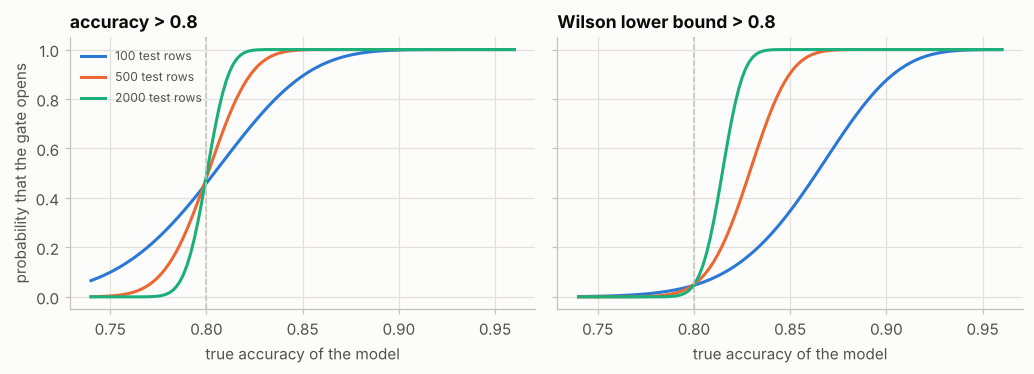

In [39]:
# EXTRA (b): probability that a gate opens, by true accuracy and test-set size
def wilson_lower(correct, m, z=1.645):
    p_hat = correct / m
    centre = p_hat + z ** 2 / (2 * m)
    spread = z * np.sqrt(p_hat * (1 - p_hat) / m + z ** 2 / (4 * m ** 2))
    return (centre - spread) / (1 + z ** 2 / m)


def opens(m, p, rule):
    correct = np.arange(m + 1)
    passing = correct / m > 0.8 if rule == "naive" else wilson_lower(correct, m) > 0.8
    return stats.binom.pmf(correct, m, p)[passing].sum()


true_p = [0.78, 0.80, 0.82, 0.85, 0.90, 0.95]
sizes = (100, 500, 2_000)
for rule, title in (("naive", "rule of the book: accuracy > 0.8"), ("wilson", "rule with the Wilson lower bound > 0.8")):
    table = pd.DataFrame({f"m = {m}": [opens(m, p, rule) for p in true_p] for m in sizes}, index=pd.Index(true_p, name="true accuracy"))
    print(title)
    print(table.round(3).to_string(), "\n")
needed = {m: int(np.min(np.arange(m + 1)[wilson_lower(np.arange(m + 1), m) > 0.8])) for m in sizes}
print("smallest number of correct predictions that opens the Wilson gate:", {m: f"{c} of {m} = {c / m:.3f}" for m, c in needed.items()})

grid = np.linspace(0.74, 0.96, 120)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True)
for ax, rule, title in zip(axes, ("naive", "wilson"), ("accuracy > 0.8", "Wilson lower bound > 0.8")):
    for color, m in zip(PALETTE, sizes):
        ax.plot(grid, [opens(m, p, rule) for p in grid], color=color, label=f"{m} test rows")
    ax.axvline(0.8, color=AXIS, ls="--", lw=1)
    ax.set_xlabel("true accuracy of the model")
    ax.set_title(title)
axes[0].set_ylabel("probability that the gate opens")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* **Rule of the book (accuracy above 0.8).** A model of true accuracy exactly 0.80 opens the gate about half the time (0.46, 0.48 and 0.49), whatever the size of the test set. With **100 test rows**, a model that is 2 points *above* the threshold (0.82) opens it only 66% of the time, and a model 2 points *below* (0.78) opens it 28% of the time: the decision is dominated by noise. With 500 rows these probabilities become 87% and 13%; with 2,000 rows 99% and 1.4%.
* **Wilson lower bound above 0.8.** A model exactly at 0.80 opens the gate only about 5% of the time (the level of the bound), for any size. To pass, the test accuracy must be **0.870 on 100 rows** (87 correct), **0.830 on 500 rows** (415) or **0.815 on 2,000 rows** (1,630): the bar is higher when the evidence is thinner. A model of true accuracy 0.85 passes 35% of the time with 100 rows, 90% with 500 and essentially always with 2,000; a model of 0.90 passes 88% of the time even with 100 rows.
* The rule with the bound is the one that matches the sentence "deploy only if the model meets the threshold": it opens only when the data *demonstrate* that the threshold is met. The price is a larger test set. The figure shows both: the naive gate's curves cross at the threshold and become steeper with more rows; the Wilson gate's curves are shifted to the right by an amount that shrinks with more rows.

**(c) The build that does not fail.** The cell runs three gate scripts as separate Python processes, the way a CI job runs them, and prints their exit codes: the book's `if/else` with `print`, the same with `sys.exit(1)` in the rejecting branch, and an `assert`.

In [40]:
# EXTRA (c): what a CI job sees: the exit code of the gate script
book_gate = """
acc = 0.51
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")
"""
exit_gate = book_gate.replace('print("Halt deployment and review")', 'print("Halt deployment and review"); raise SystemExit(1)')
assert_gate = "acc = 0.51\nassert acc > 0.8, 'accuracy below the threshold'\nprint('Auto-deploy allowed')\n"
for label, script in (("the book's if/else with print", book_gate), ("if/else with SystemExit(1)", exit_gate), ("assert", assert_gate)):
    status, out, err = run_python(script)
    print(f"{label:32s} exit code {status} | stdout: {out or '-':28s} | stderr: {err or '-'}")

the book's if/else with print    exit code 0 | stdout: Halt deployment and review   | stderr: -
if/else with SystemExit(1)       exit code 1 | stdout: Halt deployment and review   | stderr: -
assert                           exit code 1 | stdout: -                            | stderr: AssertionError: accuracy below the threshold


**Analysis of extra (c).**

* The book's `if/else` with `print` ends with **exit code 0** after printing *Halt deployment and review*: for a CI system that is a success, and the next step (the deployment) would run. The same script with `raise SystemExit(1)` in the rejecting branch ends with **exit code 1**, and an `assert` ends with exit code 1 and an `AssertionError` message on standard error. A gate that is meant to stop a release must end the process with a non-zero code.

**(d) A fuller gate.** `deployment_gate` returns a decision and the list of reasons for a refusal. Its checks are the ones of the theory table: **schema** (the number of input features), **quality** (Wilson lower bound of the accuracy above 0.80), **non-regression** (accuracy not more than 0.02 below the current model, the *champion*, on the same rows) and **behavior** (share of positive predictions within 0.10 of the share in the held-out labels). Five candidates are checked against 500 held-out rows: a model retrained on other rows, a model trained on labels with 30% flipped, the good model fed with its columns in the wrong order (a serving bug), a model trained on only 9 features, and a model that always answers the majority class.

In [41]:
# EXTRA (d): a gate with several checks, and five candidates
from sklearn.dummy import DummyClassifier

X_ci, y_ci = make_classification(n_samples=2_000, n_features=10, random_state=2024)
X_fit_ci, y_fit_ci, X_test_ci, y_test_ci = X_ci[:1_000], y_ci[:1_000], X_ci[1_000:1_500], y_ci[1_000:1_500]


def fitted_pipeline(X_rows, y_rows):
    return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_rows, y_rows)


champion = fitted_pipeline(X_fit_ci, y_fit_ci)


def deployment_gate(candidate, X_test, y_test, rows_for_candidate=None, minimum=0.80, regression_margin=0.02, rate_tolerance=0.10):
    reasons = []
    inputs = X_test if rows_for_candidate is None else rows_for_candidate
    if candidate.n_features_in_ != inputs.shape[1]:
        return False, [f"schema: the model expects {candidate.n_features_in_} features, the service sends {inputs.shape[1]}"], np.nan, np.nan
    predictions = candidate.predict(inputs)
    correct = int(np.sum(predictions == y_test))
    accuracy, lower = correct / len(y_test), float(wilson_lower(correct, len(y_test)))
    if lower <= minimum:
        reasons.append(f"quality: lower bound {lower:.3f} is not above {minimum}")
    champion_accuracy = champion.score(X_test, y_test)
    if accuracy < champion_accuracy - regression_margin:
        reasons.append(f"non-regression: {accuracy:.3f} is more than {regression_margin} below the champion's {champion_accuracy:.3f}")
    if abs(predictions.mean() - y_test.mean()) > rate_tolerance:
        reasons.append(f"behavior: {predictions.mean():.2f} positive predictions against {y_test.mean():.2f} positive labels")
    return not reasons, reasons, accuracy, lower


rng_flip = np.random.default_rng(11)
flipped = np.where(rng_flip.random(len(y_fit_ci)) < 0.30, 1 - y_fit_ci, y_fit_ci)
candidates = {
    "retrained on other rows": (fitted_pipeline(X_ci[1_500:], y_ci[1_500:]), None),
    "trained on 30% flipped labels": (fitted_pipeline(X_fit_ci, flipped), None),
    "good model, columns in the wrong order": (champion, X_test_ci[:, ::-1]),
    "trained on 9 features": (fitted_pipeline(X_fit_ci[:, :9], y_fit_ci), None),
    "always the majority class": (DummyClassifier(strategy="most_frequent").fit(X_fit_ci, y_fit_ci), None),
}
rows = []
for label, (candidate, served_rows) in candidates.items():
    ok, reasons, accuracy, lower = deployment_gate(candidate, X_test_ci, y_test_ci, served_rows)
    rows.append({"candidate": label, "accuracy": accuracy, "lower bound": lower, "decision": "deploy" if ok else "refuse", "reasons": " | ".join(reasons) or "-"})
print(f"champion: accuracy {champion.score(X_test_ci, y_test_ci):.3f} on the same {len(y_test_ci)} held-out rows")
verdicts = pd.DataFrame(rows)
print(verdicts[["candidate", "accuracy", "lower bound", "decision"]].round(3).to_string(index=False))
print()
for _, row in verdicts.iterrows():
    print(f"{row['candidate']}:\n    {row['reasons'].replace(' | ', chr(10) + '    ')}")

champion: accuracy 0.874 on the same 500 held-out rows
                             candidate  accuracy  lower bound decision
               retrained on other rows     0.874        0.848   deploy
         trained on 30% flipped labels     0.832        0.803   refuse
good model, columns in the wrong order     0.182        0.155   refuse
                 trained on 9 features       NaN          NaN   refuse
             always the majority class     0.484        0.447   refuse

retrained on other rows:
    -
trained on 30% flipped labels:
    non-regression: 0.832 is more than 0.02 below the champion's 0.874
good model, columns in the wrong order:
    quality: lower bound 0.155 is not above 0.8
    non-regression: 0.182 is more than 0.02 below the champion's 0.874
trained on 9 features:
    schema: the model expects 9 features, the service sends 10
always the majority class:
    quality: lower bound 0.447 is not above 0.8
    non-regression: 0.484 is more than 0.02 below the champion's 

**Analysis of extra (d).**

* The champion (the pipeline in production) scores **0.874** on the 500 held-out rows. The candidate **retrained on other rows** scores the same, 0.874, with a lower bound of 0.848: it is deployed.
* The candidate trained on **30% flipped labels** scores 0.832 with a lower bound of 0.803, which **passes the absolute quality gate**, and is refused by the **non-regression** gate (more than 0.02 below the champion). A threshold alone would have let a degraded model replace a better one.
* The **good model with its columns in the wrong order** scores 0.182, *below* chance (the reversed columns make the predictions anti-correlated with the labels), and fails the quality and non-regression gates. Nothing in a NumPy pipeline would have raised an error: only the metric reveals the bug (extra (e) shows how pandas input catches it earlier).
* The model trained on **9 features** is refused by the **schema** gate before any metric is computed. The **majority-class** model scores 0.484 (the share of the positive class) and fails quality and non-regression; its **behavior** check (all predictions positive, against 48% positive labels) catches a constant predictor even in a setting where its accuracy could look acceptable, such as heavily imbalanced data.
* None of the checks is expensive, and each one corresponds to a way in which real releases fail. The thresholds (0.80, 0.02, 0.10) are the business decisions of the book's last paragraph of the recipe.

**(e) Training-serving skew.** Two ways in which the artifact of the book prevents bugs, and one in which a missing step creates them. The data have columns on very different scales. A classifier is trained on standardized data; at serving time the scaler is *forgotten* (the bare classifier receives raw features) or kept (the pipeline). With pandas input, the pipeline also refuses columns in another order.

In [42]:
# EXTRA (e): a forgotten scaler, and columns in another order
X_raw, y_raw = make_classification(n_samples=1_000, n_features=6, random_state=7)
X_raw = X_raw * np.array([1000.0, 1.0, 0.01, 1.0, 50.0, 1.0]) + np.array([5000.0, 0.0, 3.0, 0.0, -200.0, 0.0])
X_a, y_a, X_b, y_b = X_raw[:700], y_raw[:700], X_raw[700:], y_raw[700:]

scaled_pipeline = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_a, y_a)
bare_classifier = LogisticRegression().fit(StandardScaler().fit(X_a).transform(X_a), y_a)  # trained on scaled rows ...
print(f"pipeline (scaler inside the artifact)        : accuracy {scaled_pipeline.score(X_b, y_b):.3f}")
print(f"bare classifier fed raw features (scaler lost): accuracy {bare_classifier.score(X_b, y_b):.3f}")

frame = pd.DataFrame(X_a, columns=list("abcdef"))
named_pipeline = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(frame, y_a)
reordered = pd.DataFrame(X_b, columns=list("abcdef"))[list("fedcba")]
try:
    named_pipeline.predict(reordered)
except ValueError as error:
    print("\ncolumns in another order:", str(error).splitlines()[0])
print("features recorded in the artifact:", list(named_pipeline.feature_names_in_))

pipeline (scaler inside the artifact)        : accuracy 0.940
bare classifier fed raw features (scaler lost): accuracy 0.523

columns in another order: The feature names should match those that were passed during fit.
features recorded in the artifact: ['a', 'b', 'c', 'd', 'e', 'f']


**Analysis of extra (e).**

* The pipeline, which carries the fitted scaler, scores **0.940** on columns with very different scales. The classifier that was trained on standardized data but receives the **raw features** (the scaler is lost between training and serving) scores **0.523**, chance. The pipeline cannot make that mistake because the preprocessing is part of the artifact; this is the practical content of the book's sentence that a single artifact "includes the entire inference logic".
* With pandas input, the pipeline records the names of the columns (`feature_names_in_`: a to f) and refuses the same data with the columns in another order (`The feature names should match those that were passed during fit.`). A NumPy array has no names, so the check does not exist there; a service that wants this protection should pass **DataFrames** at its boundary.

---
## 7. Practical exercises in model deployment

*Book: pp. 345–346; official solutions: the repository of the book.*

The book lists three exercises, each as four implementation steps, without code. The code below is the **official solution** of the book's repository. The solution of Exercise 2 reuses variables of earlier cells (`X_train`, `stream_batches` and `SGDClassifier` from recipe 4), and the extras for Exercises 2 and 3 also use `book_model`, `X_one` and `wilson_lower` from earlier extras, so the cells must run in order.

### Exercise 1: Saving and reloading a model pipeline for deployment

Serialize a trained pipeline and reload it to simulate a production environment, so that preprocessing and inference logic travel together.

In [43]:
# BOOK CODE (official solution, Exercise 1)
# Load libraries
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
pipe.fit(X, y)

# Save and reload pipeline
dump(pipe, "model_pipeline.joblib")
loaded_pipe = load("model_pipeline.joblib")

# Generate new predictions
print(loaded_pipe.predict(X[:5]))

[1 1 1 0 0]


**Analysis of Exercise 1.**

The solution prints `[1 1 1 0 0]`: the classes that the reloaded pipeline gives for the first five rows. Unlike the pipeline of recipe 6, its steps are named `scaler` and `model` instead of `scale` and `clf`: the names are arbitrary but become part of the artifact, so a service that reads `named_steps["scaler"]` depends on them.

**Extra for Exercise 1: is the reloaded pipeline really the same, also in a fresh process?** The cell compares the original and the reloaded pipeline on all 500 rows and on 10,000 random rows (probabilities, exactly), checks that the fitted scaler travelled with the model, and asks a fresh Python process to load the file and predict the first five rows.

In [44]:
# EXTRA: Exercise 1 - exactness of the round trip and a fresh-process check
random_rows = np.random.default_rng(8).normal(size=(10_000, 10))
print("probabilities identical on the 500 rows        :", np.array_equal(pipe.predict_proba(X), loaded_pipe.predict_proba(X)))
print("probabilities identical on 10,000 random rows  :", np.array_equal(pipe.predict_proba(random_rows), loaded_pipe.predict_proba(random_rows)))
print("scaler statistics travelled with the artifact  :", np.array_equal(pipe["scaler"].mean_, loaded_pipe["scaler"].mean_),
      "| first three means:", np.round(loaded_pipe["scaler"].mean_[:3], 4))
print(f"file size: {os.path.getsize('model_pipeline.joblib'):,} bytes")

np.save("first_rows.npy", X[:5])
status, out, err = run_python("import joblib, numpy as np; p = joblib.load('model_pipeline.joblib'); print(p.predict(np.load('first_rows.npy')))")
print("fresh Python process, predictions of the first five rows:", out or err)

probabilities identical on the 500 rows        : True
probabilities identical on 10,000 random rows  : True
scaler statistics travelled with the artifact  : True | first three means: [-0.0061 -0.0236 -0.0217]
file size: 1,649 bytes
fresh Python process, predictions of the first five rows: [1 1 1 0 0]


**Analysis of the extra for Exercise 1.**

The reloaded pipeline and the original give **identical probabilities** on the 500 rows and on 10,000 random rows. The fitted scaler travelled with the model (equal `mean_`, first three means -0.0061, -0.0236 and -0.0217), the whole artifact has **1,649 bytes**, and a **fresh Python process** that loads the file prints the same five classes, `[1 1 1 0 0]`. This is the test that the book's hands-on steps describe ("load them in separate Python sessions").

### Exercise 2: Monitoring model accuracy over time

Simulate streaming data and track a deployed model's accuracy on incoming batches to detect degradation. The solution replaces the classifier by `SGDClassifier(loss="hinge", alpha=1.0)`, "to make the model less accurate", and plots the accuracy of each batch.

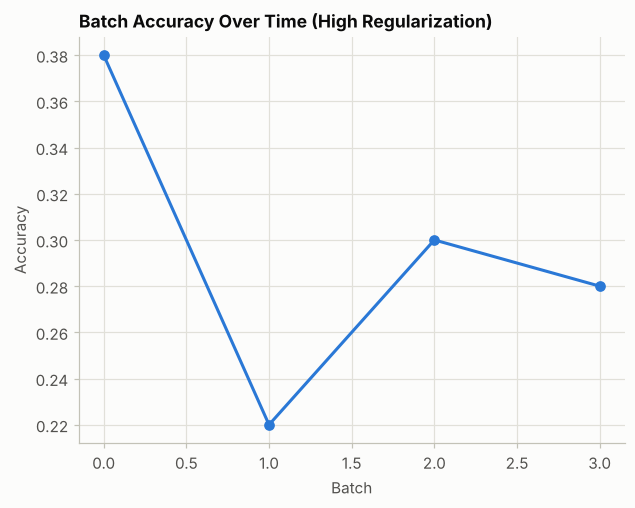

In [45]:
# BOOK CODE (official solution, Exercise 2)
# Change the SGDClassifier hyperparameters to make the model less accurate
clf = SGDClassifier(loss="hinge", alpha=1.0, random_state=2024)  # Use SVM loss and strong regularization
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
batch_scores = []
for Xb, yb in zip(stream_batches, stream_labels):
    acc = np.mean(clf.predict(Xb) == yb)
    batch_scores.append(acc)

# Plot batch accuracy
plt.plot(batch_scores, marker='o')
plt.xlabel("Batch")
plt.ylabel("Accuracy")
plt.title("Batch Accuracy Over Time (High Regularization)")
plt.grid(True)
plt.show()

**Analysis of Exercise 2.**

The solution plots four points: **0.38, 0.22, 0.30 and 0.28**. The model of recipe 4 gave 0.38, 0.30, 0.36 and 0.38 on the same stream. Both sets of values are below 0.5, because the stream is another problem (extra 4(a)); that the exercise's values are lower is not a result, because the batches have 50 rows (a standard error of about 0.07). The exercise also depends on variables of recipe 4 (`X_train`, `stream_batches`, `SGDClassifier`) and cannot run alone.

**Extra for Exercise 2: did `alpha=1.0` make the model less accurate?** The cell compares the exercise's batch accuracies with those of the model of recipe 4 on the book's stream, then repeats the comparison on the *coherent* stream of extra 4(a) (same problem as the training data) and sweeps `alpha`.

In [46]:
# EXTRA: Exercise 2 - the exercise's model against the model of recipe 4, and a sweep of alpha
exercise_scores = [float(s) for s in batch_scores]
recipe_scores = [float(np.mean(book_model.predict(xb) == yb)) for xb, yb in zip(stream_batches, stream_labels)]
print("book's stream   | recipe 4 model:", [round(s, 2) for s in recipe_scores], "| exercise 2 model:", [round(s, 2) for s in exercise_scores])

X_fit2, y_fit2, X_stream2, y_stream2 = X_one[:500], y_one[:500], X_one[500:], y_one[500:]
rows, reference_weights = [], None
for alpha in (0.0001, 0.01, 1.0, 10.0, 100.0):
    model = SGDClassifier(loss="hinge", alpha=alpha, random_state=2024).partial_fit(X_fit2, y_fit2, classes=[0, 1])
    batches = [float(np.mean(model.predict(xb) == yb)) for xb, yb in zip(np.array_split(X_stream2, 4), np.array_split(y_stream2, 4))]
    weights = model.coef_.ravel()
    reference_weights = weights if reference_weights is None else reference_weights
    rows.append({"alpha": f"{alpha:g}", "accuracy on the coherent stream": model.score(X_stream2, y_stream2), "batch accuracies": [round(b, 2) for b in batches],
                 "norm of the weights": np.linalg.norm(weights), "cosine with the weights of alpha=0.0001": weights @ reference_weights / (np.linalg.norm(weights) * np.linalg.norm(reference_weights)),
                 "intercept": model.intercept_[0], "share predicted as class 1": model.predict(X_stream2).mean()})
print("\ncoherent stream (the same problem as the training data):")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nsmallest change of accuracy that 50 rows can show: one standard error is {np.sqrt(0.84 * 0.16 / 50):.3f}")

book's stream   | recipe 4 model: [0.38, 0.3, 0.36, 0.38] | exercise 2 model: [0.38, 0.22, 0.3, 0.28]

coherent stream (the same problem as the training data):
 alpha  accuracy on the coherent stream         batch accuracies  norm of the weights  cosine with the weights of alpha=0.0001  intercept  share predicted as class 1
0.0001                            0.870 [0.86, 0.86, 0.84, 0.92]               60.400                                    1.000     -6.525                       0.455
  0.01                            0.845   [0.8, 0.82, 0.86, 0.9]                2.817                                    0.970      0.307                       0.470
     1                            0.845  [0.82, 0.9, 0.78, 0.88]                0.559                                    0.972     -0.241                       0.380
    10                            0.555   [0.5, 0.58, 0.54, 0.6]                0.106                                    0.959     -0.656                       0.000
   100    

**Analysis of the extra for Exercise 2.**

* On the book's stream the exercise's model scores **0.38, 0.22, 0.30 and 0.28** and the recipe's model **0.38, 0.30, 0.36 and 0.38**: both are below chance and differ by amounts that 50-row batches cannot resolve.
* On the **coherent stream** (the same problem as the training data) the exercise's setting, `loss="hinge", alpha=1.0`, is **as accurate as the recipe's model**: 0.845 overall (batches 0.82, 0.90, 0.78, 0.88), against 0.835 for the recipe's model. The strong regularization shrinks the weights (the norm falls from 60.4 with `alpha=0.0001` to 0.56 with `alpha=1.0`) but hardly changes their direction (cosine similarity 0.97 with the weights of `alpha=0.0001`), and a classifier depends on the direction.
* The accuracy collapses only for `alpha` of **10 or more**: 0.555 and every prediction in class 0 (the share predicted as class 1 is 0.000). The direction of the weights is still almost the same (cosine 0.96), but the weights are tiny (norm 0.106 or less) and the **unpenalized intercept** (-0.66 at `alpha=10`) now dominates the score, so every point gets the class of the intercept's sign. The setting of the exercise therefore does not "make the model less accurate" except by chance on a stream of another problem; a model that degrades the way a deployed model does needs a real drift (extra 4(c)) or a much larger `alpha`.
* One standard error of an accuracy measured on 50 rows is 0.052, so the differences between 0.82, 0.90, 0.78 and 0.88 across the batches are noise as well.

### Exercise 3: Automating deployment checks using validation thresholds

Simulate a CI/CD check that decides whether a serialized model meets a performance criterion before it is promoted to production.

In [47]:
# BOOK CODE (official solution, Exercise 3)
# Load libraries
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Train and export model
X, y = make_classification(n_samples=300, n_features=10, random_state=2024)
model = LogisticRegression()
model.fit(X, y)
dump(model, "model_ci.joblib")

# Load and validate with test data
Xt, yt = make_classification(n_samples=100, n_features=10, random_state=2025)
model_prod = load("model_ci.joblib")
pred = model_prod.predict(Xt)
acc = accuracy_score(yt, pred)
print(f"Test Accuracy: {acc:.3f}")

# Conditionally approve deployment
if acc > 0.8:
    print("Deployment approved")
else:
    print("Deployment rejected")

Test Accuracy: 0.110
Deployment rejected


**Analysis of Exercise 3.**

The solution prints *Test Accuracy: 0.110* and *Deployment rejected*. An accuracy of 0.11 means that the model is wrong on **89% of the rows**: that is much worse than chance, a model whose rule is reversed for this data. The test data come from `make_classification(..., random_state=2025)`, another problem, not held-out rows of the problem on which the model was trained, so the check rejects the model for a reason that has nothing to do with its quality.

**Extra for Exercise 3: why is the model rejected?** The test set comes from `make_classification(..., random_state=2025)`, which is **another problem**, not held-out rows of the training problem (extra 4(a) shows the same thing for the stream of recipe 4). The cell repeats the exercise's check for 200 test seeds, and then for a test set that really comes from the training population.

In [48]:
# EXTRA: Exercise 3 - the check on 200 test seeds, and on held-out rows of the same problem
outcomes = []
for seed in range(2025, 2225):
    X_other, y_other = make_classification(n_samples=100, n_features=10, random_state=seed)
    outcomes.append(accuracy_score(y_other, model.predict(X_other)))
outcomes = np.array(outcomes)
print(f"the exercise's check on 200 test seeds: accuracy mean {outcomes.mean():.3f}, sd {outcomes.std():.3f}, min {outcomes.min():.2f}, max {outcomes.max():.2f}")
print(f"approved for {np.mean(outcomes > 0.8):.1%} of the seeds, accuracy below 0.5 for {np.mean(outcomes < 0.5):.1%}; seed 2025 gives {outcomes[0]:.2f}")

X_same, y_same = make_classification(n_samples=400, n_features=10, random_state=2024)
model_same = LogisticRegression().fit(X_same[:300], y_same[:300])
acc_same = accuracy_score(y_same[300:], model_same.predict(X_same[300:]))
correct_same = int(round(acc_same * 100))
print(f"\nmodel fitted on 300 rows, tested on the other 100 rows of the same call: accuracy {acc_same:.3f} -> "
      f"{'Deployment approved' if acc_same > 0.8 else 'Deployment rejected'}; Wilson lower bound {wilson_lower(correct_same, 100):.3f}")

the exercise's check on 200 test seeds: accuracy mean 0.541, sd 0.176, min 0.09, max 0.92
approved for 13.0% of the seeds, accuracy below 0.5 for 44.5%; seed 2025 gives 0.11

model fitted on 300 rows, tested on the other 100 rows of the same call: accuracy 0.850 -> Deployment approved; Wilson lower bound 0.782


**Analysis of the extra for Exercise 3.**

* For 200 different test seeds the exercise's check gives an accuracy of **0.541 on average** (standard deviation 0.176, from 0.09 to 0.92); it **approves the model for 13% of the seeds** and gives an accuracy below 0.5 for 44.5% of them. Seed 2025 (0.11) is one of the unlucky draws. The outcome of the exercise depends on which other problem the test set happens to be, not on the model.
* A test set drawn from the training population (the last 100 rows of a 400-row call, the first 300 for training) gives an accuracy of **0.850**: *Deployment approved* by the rule of the exercise. With only 100 test rows the Wilson lower bound is **0.782**, below 0.8: the stricter gate of recipe 6 would **refuse** this model, because 100 rows cannot show that its accuracy clears 0.8 (extra 6(b): such a gate needs 87 of 100 correct). A correct design of this exercise needs held-out data from the same population, enough of it for the threshold, and a gate that fails the job.

---
## Hands-on exercises of the book, step by step

Every recipe of the chapter closes with a list of steps for the reader. This table records where this notebook performs each of them.

| Recipe | Steps proposed by the book | Where in this notebook |
|---|---|---|
| 1. Overview | clone the repository, train and export a logistic regression with `joblib`, simulate a client that loads it and asks for predictions, measure the time for one instance and for a batch, examine throughput and latency | recipe 1 listings; extras 1(a) to 1(c) |
| 2. Serialization | train a classifier, save `.pkl` and `.joblib` copies, load them in separate Python sessions, verify predictive consistency, explore ONNX export | recipe 2 listings; extras 2(a), 2(b) and 2(d); ONNX only in the theory (the packages are not dependencies of this repository) |
| 3. Scaling | train a forest with `n_jobs=1` and `n_jobs=-1` and compare the latency, compare cross-validation runtimes, optionally use Dask | recipe 3 listings; extras 3(a) and 3(b); Dask only in the theory |
| 4. Monitoring | use an incremental model, feed batches over time, track and visualize the performance, automate retraining below a threshold | recipe 4 listings; extras 4(a) to 4(e) |
| 5. Life cycle | assign a semantic version, save model, metadata and validation snapshot, simulate an upgrade and attempt to load, compare results, plan rollbacks | recipe 5 listings; extras 5(a) to 5(f) |
| 6. Pipelines | build a preprocessing-plus-model pipeline, save it as one file, load it and score it in simulated CI logic, enforce deployment conditions on a metric | recipe 6 listings; extras 6(a) to 6(e) |

---
## Choosing what to deploy and how: a decision guide

| Situation | Choice | Notes from this chapter |
|---|---|---|
| Python service, artifacts produced and loaded by you | `joblib.dump` / `load` | `compress=3` shrinks a forest by a factor of 4 or more (2(b)); `mmap_mode="r"` for several worker processes sharing a large model |
| Artifact crosses a trust boundary | no pickle: `skops.io` or ONNX; otherwise sign the file and restrict the unpickler | unpickling runs code (2(c)); a signature proves origin, not safety |
| Non-Python runtime | ONNX or PMML | check that every step converts; inference only (theory of recipe 2) |
| Pipeline with custom Python steps | functions in an importable package | lambdas and notebook functions cannot be loaded elsewhere (2(d)); `cloudpickle` is a last resort |
| One request at a time, forest model | `n_jobs=1` per process, scale with replicas, micro-batch if possible | `n_jobs=-1` makes small batches slower (3(a)); one call has a fixed cost (1(b)) |
| Large batch scoring | big batches, `n_jobs=-1` | break-even in rows depends on the machine (3(a)) |
| How big a model? | the smallest one within the noise of the best | accuracy saturates, latency and size grow linearly with the trees (3(c)) |
| Labels arrive quickly | monitor accuracy per window with a threshold derived from the normal spread | a round threshold on a small batch cries wolf (4(b)) |
| Labels arrive late or never | monitor inputs and outputs (KS, PSI, share of positives) | covariate alarms are not accuracy alarms, and concept drift is invisible to them (4(d)) |
| Model must follow a drift | update on every batch, or refit on a window after an alarm | updating only on the alarming batch was the weakest policy in 4(c); the `"optimal"` rate decays (4(e)) |
| Releasing a new version | verified loader plus a gate with a confidence bound and a champion comparison | the book's random-label gate never opens (6(a)); a threshold on a small test set is noisy (6(b)) |
| The gate says no | fail the job (`SystemExit`, `assert`) | `print` ends with exit code 0 (6(c)) |
| Library upgrade | retrain from the recorded recipe, replay the validation snapshot | cross-version loading is unsupported (5(c), 5(d)) |
| Something goes wrong in production | roll back with the registry pointer | keep the previous version (5(e)) |

---
## Chapter summary

Chapter 13 takes a trained model out of the notebook. The artifact is a **byte stream of fitted state plus references to code**, so it can be saved in one line, but it can only be loaded where the same code exists, and loading it runs code. Serving is a question of **latency, throughput and cost per call**: a call has a fixed price, batches amortize it, parallelism helps only when the work per call is large, and the model should be as small as the accuracy allows. Once deployed, a model is judged on a **stream**: a threshold on batch accuracy is a noisy test, input monitors and accuracy monitors answer different questions, and updating policies differ widely under drift. A model is a **versioned artifact with a record**: library versions, data fingerprint, evaluation on unseen data, a validation snapshot, and a way back. Finally the release is a **gate**: a pipeline exported as one object, a threshold that accounts for the uncertainty of the test set, a comparison with the model in production, and a failing exit code when the answer is no.

### Key takeaways

1. **Persisting saves state, not code.** Test the round trip on many inputs (all probabilities), in a fresh process; the book's listing compares nothing, and even a one-point comparison would miss a zero-coefficient model about 55% of the time (1(a), 2(d)).
2. **`pickle`, `joblib` and `cloudpickle` execute code on load.** Never load a file you did not produce; sign artifacts, restrict the loader, or use `skops` or ONNX when the file crosses a trust boundary (2(c)).
3. **`joblib` is not systematically faster than `pickle`** (slower for a forest, faster to load a large array); **its advantages are compression and memory mapping** (2(b)).
4. **Batch your requests.** One call costs at least about 100 microseconds for a linear model and milliseconds for a forest, and a batch spreads that over its rows (1(b), 3(a)).
5. **`n_jobs=-1` is not free.** It slowed the prediction of small batches and helped large ones; measure on the target machine (3(a), 3(b)).
6. **Serve the smallest model that is within the noise of the best** (3(c)).
7. **Simulate drift with a stream from one population.** A different `random_state` of `make_classification` is a different problem, not drift; the book's batch accuracies are below chance for that reason (4(a), exercises 2 and 3).
8. **A threshold on a small batch raises false alarms.** Derive it from the normal spread, and watch inputs as well as accuracy (4(b), 4(d)).
9. **Update continuously or on a window, not only on the alarming batch** (the weakest policy in 4(c)); the `"optimal"` learning rate decays with the number of updates, which slows adaptation in theory (4(e)).
10. **Record the real versions, a data fingerprint, a hold-out score and a checksum; verify them on load** (5(b), 5(d)).
11. **Never validate on the training rows.** The official validation snapshot of the book holds rows the model was fitted on (5(a)).
12. **A gate must account for the noise of its test set and must fail the job;** a gate that prints is not a gate (6(b), 6(c)).

### Book vs. library notes

* **Recipe 1.** The text speaks of "Python's built-in functions": `joblib` is a dependency of scikit-learn, not part of the standard library. The "test" of the round trip predicts one random point and compares it with nothing; even a comparison would miss a corrupted artifact about half of the time.
* **Recipe 2.** The artifact is a byte stream in a file, not "Python arrays". The statement that `pickle` struggles with large NumPy arrays is not borne out: the sizes are the same and `joblib` was neither systematically faster nor slower; its real advantages are compression and memory mapping. The two assertions compare five predictions only.
* **Recipe 3.** The batch is a random numeric matrix, not "text data". The printed time and the `CV Accuracy` are not reproducible: the forest inside `cross_val_score` has no `random_state`. With `n_jobs=-1` the 1,000-row batch of the listing is predicted more slowly than with `n_jobs=1` (extra 3(a)).
* **Recipe 4.** The text speaks of three batches, the code makes four; the stream comes from `make_classification(random_state=2025)`, a different problem from the training data, so the accuracies are below 0.5 and the claimed upward trend is noise. The retraining step uses the batches that were just evaluated and its effect is never measured. `warm_start` has no effect on `partial_fit`.
* **Recipe 5.** The listing that loads `load_iris` as the validation set fails with a `ValueError` for a model trained on 20 features. The official notebook replaces it by rows that belong to the training data (accuracy 1.0). The metadata hard-codes `"sklearn": "1.3.2"` instead of `sklearn.__version__`.
* **Recipe 6.** Both the inputs and the labels of the "test set" are random, so the accuracy is about 0.5 and the gate cannot open; and `print` does not fail a CI job.
* **Exercises.** Exercise 2 reuses variables of recipe 4 and its settings do not make the model less accurate on a coherent stream; Exercise 3 tests on a different problem and rejects the model for that reason.
* **Library version.** All listings and the three official exercise solutions run on scikit-learn 1.9.1; the printed values that depend on time or on unseeded randomness are not reproducible digit by digit, as explained next to each listing.

---
## References

1. Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., Chaudhary, V., Young, M., Crespo, J.-F., & Dennison, D. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems 28 (NIPS 2015)*.
2. Breck, E., Cai, S., Nielsen, E., Salib, M., & Sculley, D. (2017). The ML test score: a rubric for ML production readiness and technical debt reduction. *2017 IEEE International Conference on Big Data*.
3. Kreuzberger, D., Kühl, N., & Hirschl, S. (2023). Machine learning operations (MLOps): overview, definition, and architecture. *IEEE Access, 11*.
4. Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys, 46*(4), Article 44.
5. Rabanser, S., Günnemann, S., & Lipton, Z. C. (2019). Failing loudly: an empirical study of methods for detecting dataset shift. *Advances in Neural Information Processing Systems 32 (NeurIPS 2019)*.
6. Bifet, A., & Gavaldà, R. (2007). Learning from time-changing data with adaptive windowing. *Proceedings of the 2007 SIAM International Conference on Data Mining*, 443–448.
7. Bottou, L. (2010). Large-scale machine learning with stochastic gradient descent. In *Proceedings of COMPSTAT'2010* (pp. 177–186). Physica-Verlag.
8. Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D., & Gebru, T. (2019). Model cards for model reporting. *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\* '19)*, 220–229.
9. Dean, J., & Barroso, L. A. (2013). The tail at scale. *Communications of the ACM, 56*(2), 74–80.
10. Amdahl, G. M. (1967). Validity of the single processor approach to achieving large scale computing capabilities. *AFIPS Conference Proceedings, 30* (Spring Joint Computer Conference), 483–485.
11. Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212.
12. Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
13. Python documentation. *pickle — Python object serialization* (security warning and "Restricting Globals"). https://docs.python.org/3/library/pickle.html
14. scikit-learn User Guide. *Model persistence* (security and maintainability limitations, `InconsistentVersionWarning`). https://scikit-learn.org/stable/model_persistence.html
15. joblib documentation. *Serialization and memory-mapped loading*. https://joblib.readthedocs.io/en/latest/user_guide/persistence.html
16. skops documentation. *Secure persistence with skops*. https://skops.readthedocs.io/en/latest/persistence.html
17. Pitrou, A. (2018). PEP 574 — Pickle protocol 5 with out-of-band data. https://peps.python.org/pep-0574/